
# ADÉLIA — Conferência e preparação dos dados

Este notebook faz parte do desenvolvimento do sistema ADÉLIA (Sistema Inteligente de Apoio à Decisão).

O objetivo é realizar o carregamento, a conferência, a preparação e as primeiras análises dos dados de uma loja fictícia de eletrônicos.

A base de dados utilizada é simulada e contém informações sobre produtos, clientes, vendas, itens vendidos e estoque.

Ao longo deste notebook serão realizadas verificações de qualidade, análise de consistência, construção de indicadores financeiros e análises exploratórias iniciais.


In [1]:
import pandas as pd 
from pathlib import Path

In [2]:
# Localização da pasta principal do projeto
pasta_projeto = Path.cwd()

# Permite encontrar a pasta DATA tanto na raiz
# quanto quando o notebook estiver dentro de notebooks/
if not (pasta_projeto / "DATA").exists():
    pasta_projeto = pasta_projeto.parent

pasta_dados = pasta_projeto / "DATA"

# Verificar se a pasta existe
if not pasta_dados.exists():
    raise FileNotFoundError("A pasta DATA não foi encontrada.")

print("Pasta de dados localizada:", pasta_dados)

Pasta de dados localizada: c:\Users\danri\Documents\ADÉLIArpz\ADELIA\DATA


In [3]:
# Carregamento das tabelas
produtos = pd.read_csv(pasta_dados / "produtos.csv", encoding="utf-8-sig")

clientes = pd.read_csv(pasta_dados / "clientes.csv", encoding="utf-8-sig")

vendas = pd.read_csv(pasta_dados / "vendas.csv", encoding="utf-8-sig")

itens_venda = pd.read_csv(pasta_dados / "itens_venda.csv", encoding="utf-8-sig")

estoque = pd.read_csv(pasta_dados / "estoque.csv", encoding="utf-8-sig")

print("Todos os arquivos foram carregados!")

Todos os arquivos foram carregados!


# 1. Conhecendo a estrutura dos dados

Nesta etapa, vamos conhecer a organização das tabelas que compõem a base de dados da loja de eletrônicos, identificando a quantidade de registros, colunas e informações disponíveis.

In [4]:
# Organizando as tabelas em um dicionário
tabelas = {
    "Produtos": produtos,
    "Clientes": clientes,
    "Vendas": vendas,
    "Itens de venda": itens_venda,
    "Estoque": estoque
}

# Exibindo as dimensões
for nome, tabela in tabelas.items():

    print(f"{nome}:")
    print(f"Linhas: {tabela.shape[0]}")
    print(f"Colunas: {tabela.shape[1]}")
    print("-" * 30)

Produtos:
Linhas: 36
Colunas: 6
------------------------------
Clientes:
Linhas: 650
Colunas: 6
------------------------------
Vendas:
Linhas: 5000
Colunas: 5
------------------------------
Itens de venda:
Linhas: 9230
Colunas: 7
------------------------------
Estoque:
Linhas: 36
Colunas: 4
------------------------------


# 2. Verificação da qualidade dos dados

Nesta etapa, verificamos a integridade inicial da base, investigando valores ausentes, registros duplicados, identificadores e relacionamentos entre as tabelas.

O objetivo é identificar possíveis problemas que possam comprometer as análises posteriores.

In [5]:
for nome, tabela in tabelas.items():

    print(f"\nTabela: {nome}")

    print(tabela.isnull().sum())

for nome, tabela in tabelas.items():

    print(f"{nome}: {tabela.duplicated().sum()} registros duplicados")

for nome, tabela in tabelas.items():

    print(f"\nTabela: {nome}")

    print(tabela.dtypes)


Tabela: Produtos
produto_id                0
nome_produto              0
categoria                 0
marca                     0
custo_unitario_atual      0
preco_venda_referencia    0
dtype: int64

Tabela: Clientes
cliente_id       0
nome_cliente     0
cidade           0
estado           0
data_cadastro    0
tipo_cliente     0
dtype: int64

Tabela: Vendas
venda_id           0
data_venda         0
cliente_id         0
canal_venda        0
forma_pagamento    0
dtype: int64

Tabela: Itens de venda
item_id                    0
venda_id                   0
produto_id                 0
quantidade                 0
preco_unitario_venda       0
custo_unitario_na_venda    0
desconto_total_item        0
dtype: int64

Tabela: Estoque
produto_id               0
quantidade_disponivel    0
estoque_minimo           0
data_referencia          0
dtype: int64
Produtos: 0 registros duplicados
Clientes: 0 registros duplicados
Vendas: 0 registros duplicados
Itens de venda: 0 registros duplicados
Estoque:

In [6]:
# Relacionamentos entre as tabelas
relacionamentos = [
    ("vendas", "cliente_id", "clientes", "cliente_id"),
    ("itens_venda", "venda_id", "vendas", "venda_id"),
    ("itens_venda", "produto_id", "produtos", "produto_id"),
    ("estoque", "produto_id", "produtos", "produto_id")
]

for origem, coluna_origem, destino, coluna_destino in relacionamentos:

    registros_invalidos = ~tabelas[
        {
            "vendas": "Vendas",
            "itens_venda": "Itens de venda",
            "clientes": "Clientes",
            "produtos": "Produtos",
            "estoque": "Estoque"
        }[origem]
    ][coluna_origem].isin(
        tabelas[
            {
                "vendas": "Vendas",
                "itens_venda": "Itens de venda",
                "clientes": "Clientes",
                "produtos": "Produtos",
                "estoque": "Estoque"
            }[destino]
        ][coluna_destino]
    )

    print(
        f"{origem} -> {destino}: "
        f"{registros_invalidos.sum()} registros sem correspondência"
    )

vendas -> clientes: 0 registros sem correspondência
itens_venda -> vendas: 0 registros sem correspondência
itens_venda -> produtos: 0 registros sem correspondência
estoque -> produtos: 0 registros sem correspondência


In [7]:
# Resumo da qualidade das tabelas

resumo = []

for nome, tabela in tabelas.items():

    resumo.append({
        "Tabela": nome,
        "Registros": len(tabela),
        "Colunas": len(tabela.columns),
        "Valores ausentes": tabela.isnull().sum().sum(),
        "Registros duplicados": tabela.duplicated().sum()
    })

relatorio_qualidade = pd.DataFrame(resumo)

display(relatorio_qualidade)

,Tabela,Registros,Colunas,Valores ausentes,Registros duplicados
0,Produtos,36,6,0,0
1,Clientes,650,6,0,0
2,Vendas,5000,5,0,0
3,Itens de venda,9230,7,0,0
4,Estoque,36,4,0,0


In [8]:
# Identificadores principais de cada tabela
chaves_primarias = {
    "Produtos": (produtos, "produto_id"),
    "Clientes": (clientes, "cliente_id"),
    "Vendas": (vendas, "venda_id"),
    "Itens de venda": (itens_venda, "item_id"),
    "Estoque": (estoque, "produto_id")
}

# Verificação dos identificadores
for nome, (tabela, coluna) in chaves_primarias.items():

    duplicados = tabela[coluna].duplicated().sum()
    ausentes = tabela[coluna].isnull().sum()

    print(f"\n{nome}")
    print(f"Identificadores duplicados: {duplicados}")
    print(f"Identificadores ausentes: {ausentes}")


Produtos
Identificadores duplicados: 0
Identificadores ausentes: 0

Clientes
Identificadores duplicados: 0
Identificadores ausentes: 0

Vendas
Identificadores duplicados: 0
Identificadores ausentes: 0

Itens de venda
Identificadores duplicados: 0
Identificadores ausentes: 0

Estoque
Identificadores duplicados: 0
Identificadores ausentes: 0


# 3. Preparação dos dados

Nesta etapa, analisamos os tipos de dados, realizamos as conversões necessárias e verificamos a consistência das informações comerciais.

Também verificamos se as datas e os valores registrados seguem as regras esperadas para a base de dados.

In [9]:
# Diagnóstico dos tipos de dados

diagnostico = []

for nome, tabela in tabelas.items():

    for coluna in tabela.columns:

        exemplos = tabela[coluna].dropna().astype(str).head(2).tolist()

        diagnostico.append({
            "Tabela": nome,
            "Coluna": coluna,
            "Tipo de dado": str(tabela[coluna].dtype),
            "Exemplos": " | ".join(exemplos)
        })

# Transformando os resultados em uma tabela
diagnostico_dados = pd.DataFrame(diagnostico)

display(diagnostico_dados)

,Tabela,Coluna,Tipo de dado,Exemplos
0,Produtos,produto_id,str,P001 | P002
1,Produtos,nome_produto,str,Notebook Start 14 | Notebook Office 15
2,Produtos,categoria,str,Notebooks | Notebooks
3,Produtos,marca,str,Lenovo | Acer
4,Produtos,custo_unitario_atual,float64,2450.0 | 2780.0
5,Produtos,preco_venda_referencia,float64,3299.0 | 3699.0
6,Clientes,cliente_id,str,C0051 | C0304
7,Clientes,nome_cliente,str,Tatiana Barbosa | Henrique Costa
8,Clientes,cidade,str,Campinas | Campinas
9,Clientes,estado,str,SP | SP


In [10]:
# Colunas que representam datas em cada tabela

colunas_datas = {
    "Clientes": ["data_cadastro"],
    "Vendas": ["data_venda"],
    "Estoque": ["data_referencia"]
}

# Conversão das datas para datetime

for nome, colunas in colunas_datas.items():

    tabela = tabelas[nome]

    for coluna in colunas:

        tabela[coluna] = pd.to_datetime(
            tabela[coluna],
            format="%Y-%m-%d",
            errors="coerce"
        )

print("Conversão das datas concluída!")

Conversão das datas concluída!


In [11]:
# Conferência das colunas de datas

for nome, colunas in colunas_datas.items():

    tabela = tabelas[nome]

    for coluna in colunas:

        print(f"\nTabela: {nome}")
        print(f"Coluna: {coluna}")
        print(f"Tipo: {tabela[coluna].dtype}")
        print(f"Datas inválidas: {tabela[coluna].isna().sum()}")
        print(f"Data inicial: {tabela[coluna].min()}")
        print(f"Data final: {tabela[coluna].max()}")


Tabela: Clientes
Coluna: data_cadastro
Tipo: datetime64[us]
Datas inválidas: 0
Data inicial: 2023-01-01 00:00:00
Data final: 2026-08-31 00:00:00

Tabela: Vendas
Coluna: data_venda
Tipo: datetime64[us]
Datas inválidas: 0
Data inicial: 2024-01-01 00:00:00
Data final: 2026-10-31 00:00:00

Tabela: Estoque
Coluna: data_referencia
Tipo: datetime64[us]
Datas inválidas: 0
Data inicial: 2026-10-31 00:00:00
Data final: 2026-10-31 00:00:00


In [12]:
# Verificação de consistência dos valores comerciais

resultados = [
    {
        "Verificação": "Produtos com custo negativo",
        "Ocorrências": (produtos["custo_unitario_atual"] < 0).sum()
    },
    {
        "Verificação": "Produtos com preço negativo",
        "Ocorrências": (produtos["preco_venda_referencia"] < 0).sum()
    },
    {
        "Verificação": "Produtos com preço menor ou igual ao custo",
        "Ocorrências": (
            produtos["preco_venda_referencia"]
            <= produtos["custo_unitario_atual"]
        ).sum()
    },
    {
        "Verificação": "Itens com quantidade menor ou igual a zero",
        "Ocorrências": (itens_venda["quantidade"] <= 0).sum()
    },
    {
        "Verificação": "Itens com preço de venda negativo",
        "Ocorrências": (itens_venda["preco_unitario_venda"] < 0).sum()
    },
    {
        "Verificação": "Itens com custo negativo",
        "Ocorrências": (itens_venda["custo_unitario_na_venda"] < 0).sum()
    },
    {
        "Verificação": "Itens com desconto negativo",
        "Ocorrências": (itens_venda["desconto_total_item"] < 0).sum()
    },
    {
        "Verificação": "Descontos superiores ao valor bruto do item",
        "Ocorrências": (
            itens_venda["desconto_total_item"]
            > itens_venda["quantidade"] * itens_venda["preco_unitario_venda"]
        ).sum()
    },
    {
        "Verificação": "Estoque com quantidade negativa",
        "Ocorrências": (estoque["quantidade_disponivel"] < 0).sum()
    },
    {
        "Verificação": "Estoque mínimo negativo",
        "Ocorrências": (estoque["estoque_minimo"] < 0).sum()
    }
]

relatorio_consistencia = pd.DataFrame(resultados)

display(relatorio_consistencia)

,Verificação,Ocorrências
0,Produtos com custo negativo,0
1,Produtos com preço negativo,0
2,Produtos com preço menor ou igual ao custo,0
3,Itens com quantidade menor ou igual a zero,0
4,Itens com preço de venda negativo,0
5,Itens com custo negativo,0
6,Itens com desconto negativo,0
7,Descontos superiores ao valor bruto do item,0
8,Estoque com quantidade negativa,0
9,Estoque mínimo negativo,0


In [13]:
# Relacionando vendas com a data de cadastro dos clientes

vendas_clientes = vendas.merge(
    clientes[["cliente_id", "data_cadastro"]],
    on="cliente_id",
    how="left",
    validate="many_to_one"
)

# Identificando vendas anteriores ao cadastro
vendas_anteriores = vendas_clientes[
    vendas_clientes["data_venda"] < vendas_clientes["data_cadastro"]
]

print("Vendas anteriores ao cadastro:", len(vendas_anteriores))

Vendas anteriores ao cadastro: 0


# 4. Construção dos indicadores financeiros

Nesta etapa, calculamos os principais indicadores financeiros a partir dos itens vendidos.

São considerados o faturamento bruto, os descontos, o faturamento líquido, os custos, o lucro bruto estimado e a margem bruta.

Esses indicadores permitem compreender o desempenho financeiro da loja e servirão de base para as análises posteriores.

In [14]:
# Cálculo das métricas financeiras por item

# Valor bruto do item
itens_venda["faturamento_bruto_item"] = (
    itens_venda["quantidade"] *
    itens_venda["preco_unitario_venda"]
)

# Valor após a aplicação do desconto
itens_venda["faturamento_liquido_item"] = (
    itens_venda["faturamento_bruto_item"] -
    itens_venda["desconto_total_item"]
)

# Custo total dos produtos vendidos
itens_venda["custo_total_item"] = (
    itens_venda["quantidade"] *
    itens_venda["custo_unitario_na_venda"]
)

# Lucro bruto estimado por item
itens_venda["lucro_bruto_item"] = (
    itens_venda["faturamento_liquido_item"] -
    itens_venda["custo_total_item"]
)

print("Métricas financeiras calculadas!")

Métricas financeiras calculadas!


In [15]:
# Indicadores gerais da loja

faturamento_bruto = itens_venda["faturamento_bruto_item"].sum()

descontos = itens_venda["desconto_total_item"].sum()

faturamento_liquido = itens_venda["faturamento_liquido_item"].sum()

custo_total = itens_venda["custo_total_item"].sum()

lucro_bruto = itens_venda["lucro_bruto_item"].sum()

quantidade_vendida = itens_venda["quantidade"].sum()

numero_vendas = vendas["venda_id"].nunique()

clientes_ativos = vendas["cliente_id"].nunique()

ticket_medio = faturamento_liquido / numero_vendas

margem_bruta = (
    lucro_bruto / faturamento_liquido
) * 100

# Organizando os indicadores
indicadores_gerais = pd.DataFrame({
    "Indicador": [
        "Faturamento bruto",
        "Descontos concedidos",
        "Faturamento líquido",
        "Custo total dos produtos",
        "Lucro bruto estimado",
        "Margem bruta (%)",
        "Quantidade total vendida",
        "Número de vendas",
        "Clientes que realizaram compras",
        "Ticket médio"
    ],

    "Valor": [
        faturamento_bruto,
        descontos,
        faturamento_liquido,
        custo_total,
        lucro_bruto,
        margem_bruta,
        quantidade_vendida,
        numero_vendas,
        clientes_ativos,
        ticket_medio
    ]
})

display(indicadores_gerais.round(2))

,Indicador,Valor
0,Faturamento bruto,14868800.07
1,Descontos concedidos,368881.43
2,Faturamento líquido,14499918.64
3,Custo total dos produtos,10840509.00
4,Lucro bruto estimado,3659409.64
5,Margem bruta (%),25.24
6,Quantidade total vendida,11001.00
7,Número de vendas,5000.00
8,Clientes que realizaram compras,602.00
9,Ticket médio,2899.98


In [16]:
# Identificação de itens com lucro bruto negativo

itens_com_prejuizo = itens_venda[
    itens_venda["lucro_bruto_item"] < 0
]

itens_sem_lucro = itens_venda[
    itens_venda["lucro_bruto_item"] == 0
]

print(
    "Itens com lucro bruto negativo:",
    len(itens_com_prejuizo)
)

print(
    "Itens sem lucro bruto:",
    len(itens_sem_lucro)
)

Itens com lucro bruto negativo: 0
Itens sem lucro bruto: 0


In [17]:
# Funções para formatar os valores

def formatar_moeda(valor):
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def formatar_inteiro(valor):
    return f"{valor:,.0f}".replace(",", ".")


def formatar_percentual(valor):
    return f"{valor:.2f}%".replace(".", ",")


# Definindo o formato de cada indicador
formatadores = {
    "Faturamento bruto": formatar_moeda,
    "Descontos concedidos": formatar_moeda,
    "Faturamento líquido": formatar_moeda,
    "Custo total dos produtos": formatar_moeda,
    "Lucro bruto estimado": formatar_moeda,
    "Margem bruta (%)": formatar_percentual,
    "Quantidade total vendida": formatar_inteiro,
    "Número de vendas": formatar_inteiro,
    "Clientes que realizaram compras": formatar_inteiro,
    "Ticket médio": formatar_moeda
}


# Criando uma cópia para apresentação
indicadores_formatados = indicadores_gerais.copy()

indicadores_formatados["Valor"] = [
    formatadores[indicador](valor)
    for indicador, valor in zip(
        indicadores_formatados["Indicador"],
        indicadores_formatados["Valor"]
    )
]

display(indicadores_formatados)

,Indicador,Valor
0,Faturamento bruto,"R$ 14.868.800,07"
1,Descontos concedidos,"R$ 368.881,43"
2,Faturamento líquido,"R$ 14.499.918,64"
3,Custo total dos produtos,"R$ 10.840.509,00"
4,Lucro bruto estimado,"R$ 3.659.409,64"
5,Margem bruta (%),"25,24%"
6,Quantidade total vendida,11.001
7,Número de vendas,5.000
8,Clientes que realizaram compras,602
9,Ticket médio,"R$ 2.899,98"


# 5. Análise Exploratória de Dados (EDA)

Nesta etapa, iniciamos a exploração dos dados para compreender melhor o comportamento da loja.

Por meio de análises estatísticas, agrupamentos e visualizações, buscamos identificar padrões, tendências e informações relevantes que possam auxiliar na tomada de decisão.

# 5.1 Análise temporal das vendas.

In [18]:
# Relacionando as vendas com seus respectivos itens

vendas_detalhadas = itens_venda.merge(
    vendas[
        [
            "venda_id",
            "data_venda",
            "cliente_id",
            "canal_venda",
            "forma_pagamento"
        ]
    ],
    on="venda_id",
    how="left",
    validate="many_to_one"
)

print("Relacionamento concluído!")

display(vendas_detalhadas.head())

Relacionamento concluído!


,item_id,venda_id,produto_id,quantidade,preco_unitario_venda,custo_unitario_na_venda,desconto_total_item,faturamento_bruto_item,faturamento_liquido_item,custo_total_item,lucro_bruto_item,data_venda,cliente_id,canal_venda,forma_pagamento
0,I0000001,V000001,P001,1,3204.55,2450.0,0.00,3204.55,3204.55,2450.0,754.55,2024-01-01,C0374,Loja física,Cartão de crédito
1,I0000002,V000001,P028,1,38.37,18.0,1.53,38.37,36.84,18.0,18.84,2024-01-01,C0374,Loja física,Cartão de crédito
2,I0000003,V000001,P027,3,76.63,42.0,0.00,229.89,229.89,126.0,103.89,2024-01-01,C0374,Loja física,Cartão de crédito
3,I0000004,V000002,P035,1,437.77,310.0,0.00,437.77,437.77,310.0,127.77,2024-01-01,C0140,Loja física,Cartão de crédito
4,I0000005,V000003,P034,1,48.24,28.0,3.86,48.24,44.38,28.0,16.38,2024-01-01,C0180,Loja física,Cartão de débito


In [19]:
# Criando uma coluna para identificar o mês e o ano

vendas_detalhadas["mes"] = (
    vendas_detalhadas["data_venda"]
    .dt.to_period("M")
    .astype(str)
)

# Agrupando as informações por mês

vendas_mensais = (
    vendas_detalhadas
    .groupby("mes")
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),

        quantidade_vendida=(
            "quantidade", "sum"
        ),

        numero_vendas=(
            "venda_id", "nunique"
        ),

        clientes_unicos=(
            "cliente_id", "nunique"
        )
    )
    .reset_index()
)

# Calculando o ticket médio mensal

vendas_mensais["ticket_medio"] = (
    vendas_mensais["faturamento_liquido"] /
    vendas_mensais["numero_vendas"]
)

display(vendas_mensais.head(10))

,mes,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,ticket_medio
0,2024-01,369447.21,316,140,95,2638.908643
1,2024-02,282872.23,210,108,84,2619.187315
2,2024-03,387433.88,312,137,102,2827.984526
3,2024-04,350965.06,300,134,98,2619.142239
4,2024-05,405360.62,288,129,102,3142.330388
5,2024-06,432779.67,310,127,95,3407.713937
6,2024-07,395000.27,312,144,110,2743.057431
7,2024-08,461348.18,352,153,122,3015.347582
8,2024-09,472131.51,306,146,120,3233.777466
9,2024-10,328406.86,257,127,107,2585.880787


In [20]:
# Criando uma cópia para apresentação

vendas_mensais_formatadas = vendas_mensais.copy()

# Formatação dos valores
vendas_mensais_formatadas["faturamento_liquido"] = (
    vendas_mensais_formatadas["faturamento_liquido"]
    .apply(formatar_moeda)
)

vendas_mensais_formatadas["ticket_medio"] = (
    vendas_mensais_formatadas["ticket_medio"]
    .apply(formatar_moeda)
)

vendas_mensais_formatadas["quantidade_vendida"] = (
    vendas_mensais_formatadas["quantidade_vendida"]
    .apply(formatar_inteiro)
)

vendas_mensais_formatadas["numero_vendas"] = (
    vendas_mensais_formatadas["numero_vendas"]
    .apply(formatar_inteiro)
)

vendas_mensais_formatadas["clientes_unicos"] = (
    vendas_mensais_formatadas["clientes_unicos"]
    .apply(formatar_inteiro)
)

display(vendas_mensais_formatadas)

,mes,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,ticket_medio
0,2024-01,"R$ 369.447,21",316,140,95,"R$ 2.638,91"
1,2024-02,"R$ 282.872,23",210,108,84,"R$ 2.619,19"
2,2024-03,"R$ 387.433,88",312,137,102,"R$ 2.827,98"
3,2024-04,"R$ 350.965,06",300,134,98,"R$ 2.619,14"
4,2024-05,"R$ 405.360,62",288,129,102,"R$ 3.142,33"
5,2024-06,"R$ 432.779,67",310,127,95,"R$ 3.407,71"
6,2024-07,"R$ 395.000,27",312,144,110,"R$ 2.743,06"
7,2024-08,"R$ 461.348,18",352,153,122,"R$ 3.015,35"
8,2024-09,"R$ 472.131,51",306,146,120,"R$ 3.233,78"
9,2024-10,"R$ 328.406,86",257,127,107,"R$ 2.585,88"


In [21]:
import matplotlib.pyplot as plt

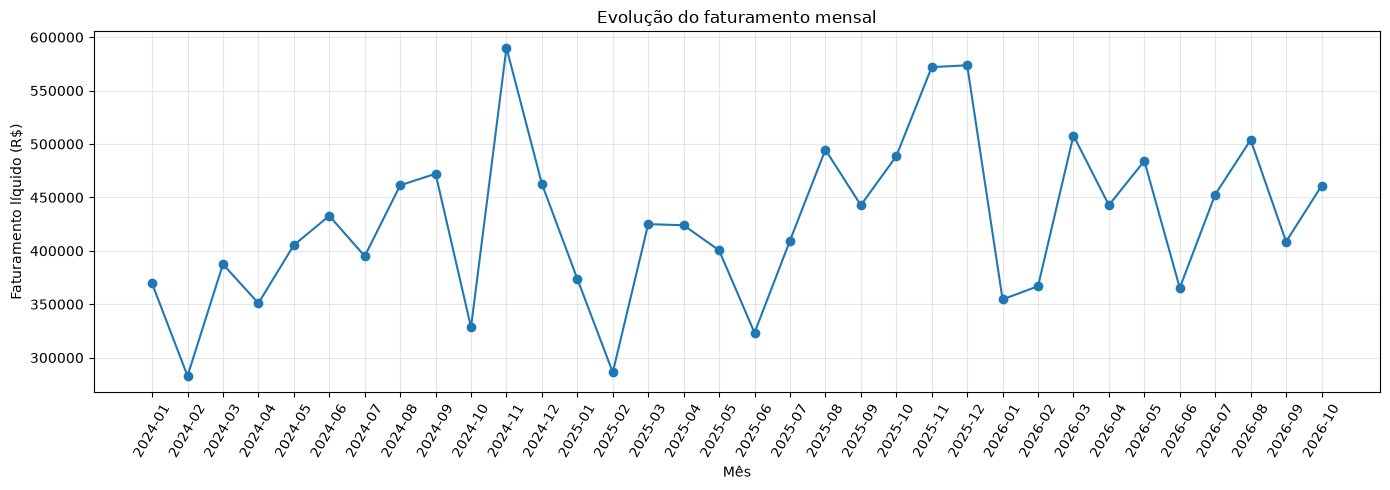

In [22]:
# Gráfico de faturamento mensal

plt.figure(figsize=(14, 5))

plt.plot(
    vendas_mensais["mes"],
    vendas_mensais["faturamento_liquido"],
    marker="o"
)

plt.title("Evolução do faturamento mensal")
plt.xlabel("Mês")
plt.ylabel("Faturamento líquido (R$)")

plt.xticks(rotation=60)

plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.show()

In [23]:
# Identificando os dez meses com maior faturamento

dez_melhores_meses = (
    vendas_mensais
    .nlargest(10, "faturamento_liquido")
)

display(dez_melhores_meses)

,mes,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,ticket_medio
10,2024-11,590136.82,440,196,142,3010.902143
23,2025-12,573747.17,422,193,145,2972.783264
22,2025-11,571954.37,433,191,159,2994.525497
26,2026-03,507953.64,383,163,144,3116.280000
31,2026-08,503877.67,408,190,172,2651.987737
19,2025-08,494653.14,393,182,144,2717.874396
21,2025-10,488593.43,344,159,127,3072.914654
28,2026-05,484199.21,326,156,138,3103.841090
8,2024-09,472131.51,306,146,120,3233.777466
11,2024-12,462660.56,345,168,131,2753.931905


In [24]:
# Agrupando as vendas por canal

desempenho_canais = (
    vendas_detalhadas
    .groupby("canal_venda")
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),

        quantidade_vendida=(
            "quantidade", "sum"
        ),

        numero_vendas=(
            "venda_id", "nunique"
        ),

        clientes_unicos=(
            "cliente_id", "nunique"
        )
    )
    .reset_index()
)

# Calculando o ticket médio por canal

desempenho_canais["ticket_medio"] = (
    desempenho_canais["faturamento_liquido"] /
    desempenho_canais["numero_vendas"]
)

# Calculando a participação de cada canal no faturamento

desempenho_canais["participacao_faturamento"] = (
    desempenho_canais["faturamento_liquido"] /
    desempenho_canais["faturamento_liquido"].sum()
) * 100

# Ordenando os canais pelo maior faturamento

desempenho_canais = desempenho_canais.sort_values(
    by="faturamento_liquido",
    ascending=False
)

display(desempenho_canais)

,canal_venda,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,ticket_medio,participacao_faturamento
0,Loja física,10483734.07,8053,3635,585,2884.108410,72.30202
1,Online,4016184.57,2948,1365,479,2942.259758,27.69798


In [25]:
# Criando uma cópia para apresentação dos resultados
desempenho_canais_formatado = desempenho_canais.copy()

# Formatação dos valores monetários
desempenho_canais_formatado["faturamento_liquido"] = (
    desempenho_canais_formatado["faturamento_liquido"]
    .apply(formatar_moeda)
)

desempenho_canais_formatado["ticket_medio"] = (
    desempenho_canais_formatado["ticket_medio"]
    .apply(formatar_moeda)
)

# Formatação das quantidades
colunas_inteiras = [
    "quantidade_vendida",
    "numero_vendas",
    "clientes_unicos"
]

for coluna in colunas_inteiras:
    desempenho_canais_formatado[coluna] = (
        desempenho_canais_formatado[coluna]
        .apply(formatar_inteiro)
    )

# Formatação dos percentuais
desempenho_canais_formatado["participacao_faturamento"] = (
    desempenho_canais_formatado["participacao_faturamento"]
    .apply(formatar_percentual)
)

display(desempenho_canais_formatado)

,canal_venda,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,ticket_medio,participacao_faturamento
0,Loja física,"R$ 10.483.734,07",8.053,3.635,585,"R$ 2.884,11","72,30%"
1,Online,"R$ 4.016.184,57",2.948,1.365,479,"R$ 2.942,26","27,70%"


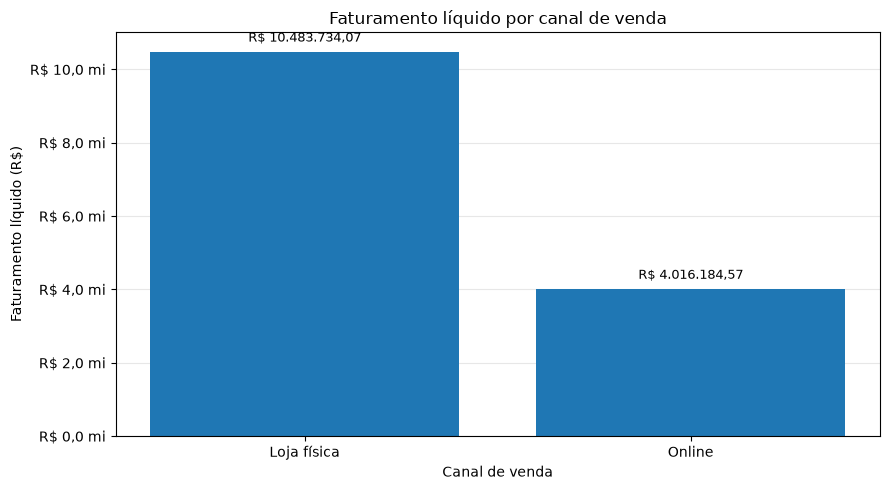

In [26]:
# Comparação do faturamento líquido por canal

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.bar(
    desempenho_canais["canal_venda"],
    desempenho_canais["faturamento_liquido"]
)

# Adicionando os valores sobre as barras
rotulos = [
    formatar_moeda(valor)
    for valor in desempenho_canais["faturamento_liquido"]
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=9
)

ax.set_title("Faturamento líquido por canal de venda")
ax.set_xlabel("Canal de venda")
ax.set_ylabel("Faturamento líquido (R$)")

# Formatação dos valores do eixo vertical em milhões
from matplotlib.ticker import FuncFormatter

ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, pos: (
            f"R$ {valor / 1_000_000:.1f}".replace(".", ",") + " mi"
        )
    )
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 5.3 Análise de desempenho por categoria de produto

Nesta etapa, vamos investigar o desempenho comercial das diferentes categorias de produtos da loja.

Serão analisados o faturamento líquido, a quantidade vendida, o número de vendas, os custos, o lucro bruto e a margem bruta de cada categoria.

O objetivo é identificar quais categorias possuem maior contribuição para os resultados financeiros da loja e compreender melhor a composição do faturamento.

In [27]:
# Relacionando os itens vendidos com as informações dos produtos

itens_produtos = itens_venda.merge(
    produtos[
        [
            "produto_id",
            "nome_produto",
            "categoria",
            "marca"
        ]
    ],
    on="produto_id",
    how="left",
    validate="many_to_one"
)

# Agrupando os resultados por categoria

desempenho_categorias = (
    itens_produtos
    .groupby("categoria")
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),
        quantidade_vendida=(
            "quantidade", "sum"
        ),
        numero_vendas=(
            "venda_id", "nunique"
        ),
        produtos_distintos=(
            "produto_id", "nunique"
        ),
        custo_total=(
            "custo_total_item", "sum"
        ),
        lucro_bruto=(
            "lucro_bruto_item", "sum"
        )
    )
    .reset_index()
)

# Calculando a margem bruta e a participação no faturamento

desempenho_categorias["margem_bruta"] = (
    desempenho_categorias["lucro_bruto"] /
    desempenho_categorias["faturamento_liquido"]
) * 100

desempenho_categorias["participacao_faturamento"] = (
    desempenho_categorias["faturamento_liquido"] /
    desempenho_categorias["faturamento_liquido"].sum()
) * 100

# Ordenando pelo maior faturamento

desempenho_categorias = desempenho_categorias.sort_values(
    by="faturamento_liquido",
    ascending=False
)

display(desempenho_categorias)

,categoria,faturamento_liquido,quantidade_vendida,numero_vendas,produtos_distintos,custo_total,lucro_bruto,margem_bruta,participacao_faturamento
2,Notebooks,5624803.39,1284,1169,6,4331670.0,1293133.39,22.989842,38.791965
4,Smartphones,3163556.73,1766,1563,6,2316740.0,846816.73,26.767869,21.817755
1,Computadores,2569976.46,704,676,4,1964960.0,605016.46,23.541712,17.724075
3,Periféricos,1473852.75,2540,1816,6,1024490.0,449362.75,30.488985,10.164559
5,Tablets,1309053.04,835,779,4,983580.0,325473.04,24.863243,9.028003
0,Acessórios,358676.27,3872,2143,10,219069.0,139607.27,38.922918,2.473643


In [28]:
# Criando uma cópia formatada para apresentação

desempenho_categorias_formatado = desempenho_categorias.copy()

# Formatação dos valores monetários
colunas_monetarias = [
    "faturamento_liquido",
    "custo_total",
    "lucro_bruto"
]

for coluna in colunas_monetarias:
    desempenho_categorias_formatado[coluna] = (
        desempenho_categorias_formatado[coluna]
        .apply(formatar_moeda)
    )

# Formatação das quantidades
colunas_inteiras = [
    "quantidade_vendida",
    "numero_vendas",
    "produtos_distintos"
]

for coluna in colunas_inteiras:
    desempenho_categorias_formatado[coluna] = (
        desempenho_categorias_formatado[coluna]
        .apply(formatar_inteiro)
    )

# Formatação dos percentuais
colunas_percentuais = [
    "margem_bruta",
    "participacao_faturamento"
]

for coluna in colunas_percentuais:
    desempenho_categorias_formatado[coluna] = (
        desempenho_categorias_formatado[coluna]
        .apply(formatar_percentual)
    )

display(desempenho_categorias_formatado)

,categoria,faturamento_liquido,quantidade_vendida,numero_vendas,produtos_distintos,custo_total,lucro_bruto,margem_bruta,participacao_faturamento
2,Notebooks,"R$ 5.624.803,39",1.284,1.169,6,"R$ 4.331.670,00","R$ 1.293.133,39","22,99%","38,79%"
4,Smartphones,"R$ 3.163.556,73",1.766,1.563,6,"R$ 2.316.740,00","R$ 846.816,73","26,77%","21,82%"
1,Computadores,"R$ 2.569.976,46",704,676,4,"R$ 1.964.960,00","R$ 605.016,46","23,54%","17,72%"
3,Periféricos,"R$ 1.473.852,75",2.540,1.816,6,"R$ 1.024.490,00","R$ 449.362,75","30,49%","10,16%"
5,Tablets,"R$ 1.309.053,04",835,779,4,"R$ 983.580,00","R$ 325.473,04","24,86%","9,03%"
0,Acessórios,"R$ 358.676,27",3.872,2.143,10,"R$ 219.069,00","R$ 139.607,27","38,92%","2,47%"


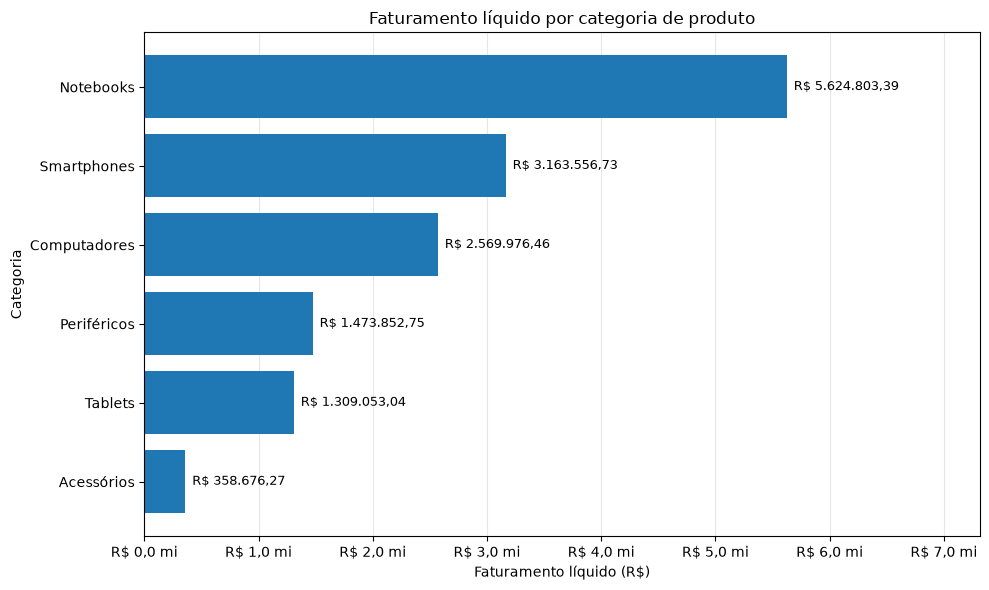

In [29]:
# Comparação do faturamento líquido por categoria

fig, ax = plt.subplots(figsize=(10, 6))

barras = ax.barh(
    desempenho_categorias["categoria"],
    desempenho_categorias["faturamento_liquido"]
)

# Colocando a maior categoria no topo
ax.invert_yaxis()

# Adicionando os valores sobre as barras
rotulos = [
    formatar_moeda(valor)
    for valor in desempenho_categorias["faturamento_liquido"]
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=9
)

# Formatando o eixo horizontal em milhões de reais
from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, pos: (
            f"R$ {valor / 1_000_000:.1f}".replace(".", ",") + " mi"
        )
    )
)

ax.set_title("Faturamento líquido por categoria de produto")
ax.set_xlabel("Faturamento líquido (R$)")
ax.set_ylabel("Categoria")

ax.set_xlim(
    0,
    desempenho_categorias["faturamento_liquido"].max() * 1.30
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 5.4 Análise de desempenho por produto

Nesta etapa, vamos analisar individualmente os produtos comercializados pela loja, identificando aqueles que apresentam maior faturamento, volume de vendas e lucro bruto.

O objetivo é identificar os produtos de maior contribuição para os resultados financeiros e comerciais da loja, permitindo uma análise mais detalhada do desempenho do catálogo.

In [30]:
# Agrupando os resultados por produto

desempenho_produtos = (
    itens_produtos
    .groupby(
        ["produto_id", "nome_produto", "categoria", "marca"]
    )
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),
        quantidade_vendida=(
            "quantidade", "sum"
        ),
        numero_vendas=(
            "venda_id", "nunique"
        ),
        custo_total=(
            "custo_total_item", "sum"
        ),
        lucro_bruto=(
            "lucro_bruto_item", "sum"
        )
    )
    .reset_index()
)

# Calculando a margem bruta de cada produto

desempenho_produtos["margem_bruta"] = (
    desempenho_produtos["lucro_bruto"] /
    desempenho_produtos["faturamento_liquido"]
) * 100

# Calculando a participação no faturamento total

desempenho_produtos["participacao_faturamento"] = (
    desempenho_produtos["faturamento_liquido"] /
    desempenho_produtos["faturamento_liquido"].sum()
) * 100

# Ordenando do maior para o menor faturamento

desempenho_produtos = desempenho_produtos.sort_values(
    by="faturamento_liquido",
    ascending=False
)

# Selecionando os dez produtos de maior faturamento

dez_melhores_produtos = desempenho_produtos.head(10)

display(dez_melhores_produtos)

,produto_id,nome_produto,categoria,marca,faturamento_liquido,quantidade_vendida,numero_vendas,custo_total,lucro_bruto,margem_bruta,participacao_faturamento
2,P003,Notebook Pro 15,Notebooks,Dell,1193510.69,237,237,912450.0,281060.69,23.549072,8.231154
5,P006,Notebook Work 16,Notebooks,Lenovo,1102431.68,238,238,844900.0,257531.68,23.360330,7.603020
3,P004,Notebook Gamer G5,Notebooks,Acer,1034591.80,172,172,799800.0,234791.80,22.694149,7.135156
10,P011,Smartphone Max E,Smartphones,Xiaomi,939218.34,334,334,701400.0,237818.34,25.320879,6.477404
14,P015,Computador Desktop Pro,Computadores,Lenovo,929212.12,218,218,708500.0,220712.12,23.752609,6.408395
1,P002,Notebook Office 15,Notebooks,Acer,851945.94,239,239,664420.0,187525.94,22.011483,5.875522
21,P022,Monitor Gamer 27,Periféricos,AOC,824033.29,531,446,594720.0,229313.29,27.828158,5.683020
4,P005,Notebook Slim 13,Notebooks,ASUS,749591.46,180,180,576000.0,173591.46,23.158143,5.169625
0,P001,Notebook Start 14,Notebooks,Lenovo,692731.82,218,218,534100.0,158631.82,22.899456,4.777488
17,P018,Tablet Pro 11,Tablets,Apple,657582.44,219,219,514650.0,142932.44,21.736049,4.535077


In [31]:
# Criando uma cópia formatada para apresentação

dez_melhores_produtos_formatado = dez_melhores_produtos.copy()

# Formatação dos valores monetários
colunas_monetarias = [
    "faturamento_liquido",
    "custo_total",
    "lucro_bruto"
]

for coluna in colunas_monetarias:
    dez_melhores_produtos_formatado[coluna] = (
        dez_melhores_produtos_formatado[coluna]
        .apply(formatar_moeda)
    )

# Formatação das quantidades
colunas_inteiras = [
    "quantidade_vendida",
    "numero_vendas"
]

for coluna in colunas_inteiras:
    dez_melhores_produtos_formatado[coluna] = (
        dez_melhores_produtos_formatado[coluna]
        .apply(formatar_inteiro)
    )

# Formatação dos percentuais
colunas_percentuais = [
    "margem_bruta",
    "participacao_faturamento"
]

for coluna in colunas_percentuais:
    dez_melhores_produtos_formatado[coluna] = (
        dez_melhores_produtos_formatado[coluna]
        .apply(formatar_percentual)
    )

display(dez_melhores_produtos_formatado)

,produto_id,nome_produto,categoria,marca,faturamento_liquido,quantidade_vendida,numero_vendas,custo_total,lucro_bruto,margem_bruta,participacao_faturamento
2,P003,Notebook Pro 15,Notebooks,Dell,"R$ 1.193.510,69",237,237,"R$ 912.450,00","R$ 281.060,69","23,55%","8,23%"
5,P006,Notebook Work 16,Notebooks,Lenovo,"R$ 1.102.431,68",238,238,"R$ 844.900,00","R$ 257.531,68","23,36%","7,60%"
3,P004,Notebook Gamer G5,Notebooks,Acer,"R$ 1.034.591,80",172,172,"R$ 799.800,00","R$ 234.791,80","22,69%","7,14%"
10,P011,Smartphone Max E,Smartphones,Xiaomi,"R$ 939.218,34",334,334,"R$ 701.400,00","R$ 237.818,34","25,32%","6,48%"
14,P015,Computador Desktop Pro,Computadores,Lenovo,"R$ 929.212,12",218,218,"R$ 708.500,00","R$ 220.712,12","23,75%","6,41%"
1,P002,Notebook Office 15,Notebooks,Acer,"R$ 851.945,94",239,239,"R$ 664.420,00","R$ 187.525,94","22,01%","5,88%"
21,P022,Monitor Gamer 27,Periféricos,AOC,"R$ 824.033,29",531,446,"R$ 594.720,00","R$ 229.313,29","27,83%","5,68%"
4,P005,Notebook Slim 13,Notebooks,ASUS,"R$ 749.591,46",180,180,"R$ 576.000,00","R$ 173.591,46","23,16%","5,17%"
0,P001,Notebook Start 14,Notebooks,Lenovo,"R$ 692.731,82",218,218,"R$ 534.100,00","R$ 158.631,82","22,90%","4,78%"
17,P018,Tablet Pro 11,Tablets,Apple,"R$ 657.582,44",219,219,"R$ 514.650,00","R$ 142.932,44","21,74%","4,54%"


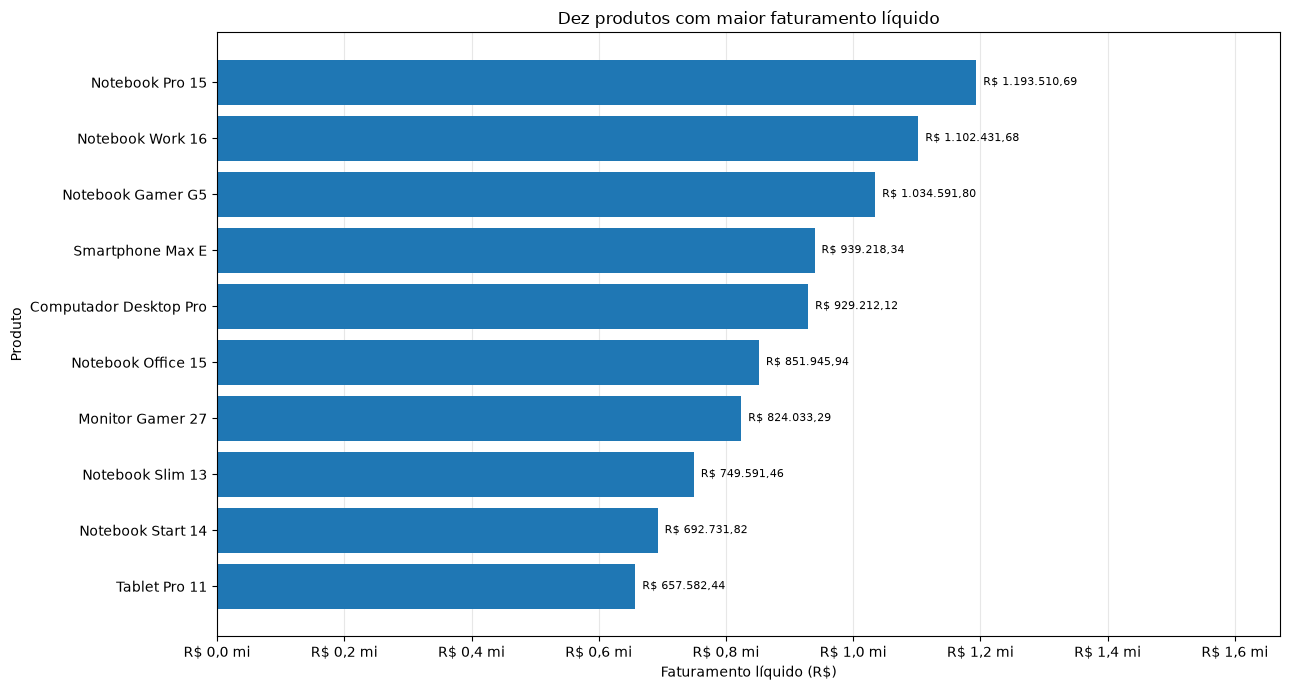

In [32]:
# Comparação do faturamento líquido dos dez melhores produtos

fig, ax = plt.subplots(figsize=(13, 7))

barras = ax.barh(
    dez_melhores_produtos["nome_produto"],
    dez_melhores_produtos["faturamento_liquido"]
)

# Colocando o produto de maior faturamento no topo
ax.invert_yaxis()

# Adicionando os valores monetários nas barras
rotulos = [
    formatar_moeda(valor)
    for valor in dez_melhores_produtos["faturamento_liquido"]
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=8
)

# Formatando o eixo horizontal em milhões de reais
from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, pos: (
            f"R$ {valor / 1_000_000:.1f}".replace(".", ",") + " mi"
        )
    )
)

ax.set_title("Dez produtos com maior faturamento líquido")
ax.set_xlabel("Faturamento líquido (R$)")
ax.set_ylabel("Produto")

ax.set_xlim(
    0,
    dez_melhores_produtos["faturamento_liquido"].max() * 1.40
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Síntese da análise de desempenho por produto

A análise dos dez produtos com maior faturamento demonstrou uma concentração significativa dos resultados comerciais em determinados itens do catálogo.

O Notebook Pro 15 apresentou o maior faturamento individual, totalizando R$ 1.193.510,69. Já o Monitor Gamer 27 destacou-se pela maior quantidade vendida entre os produtos analisados, com 531 unidades, e pela maior margem bruta, de 27,83%.

Também foi identificado que seis dos dez produtos selecionados pertencem à categoria de notebooks.

Em conjunto, os dez produtos representam aproximadamente 61,90% do faturamento total da loja.

Esses resultados permitem identificar produtos de maior contribuição financeira e demonstram a importância de avaliar diferentes indicadores, como faturamento, quantidade vendida e margem bruta, para compreender o desempenho comercial do catálogo.

## 5.5 Análise do perfil e comportamento dos clientes

Nesta etapa, vamos investigar o comportamento dos clientes da loja, considerando seus tipos de cadastro e sua participação nos resultados comerciais.

Serão analisados o faturamento gerado, a quantidade de produtos adquiridos, o número de compras, o ticket médio e a contribuição financeira de cada grupo de clientes.

O objetivo é identificar os grupos de maior relevância comercial e compreender como os clientes contribuem para os resultados da loja.

In [33]:
# Relacionando as vendas com as informações dos clientes

vendas_clientes = vendas_detalhadas.merge(
    clientes[
        [
            "cliente_id",
            "nome_cliente",
            "cidade",
            "estado",
            "tipo_cliente"
        ]
    ],
    on="cliente_id",
    how="left",
    validate="many_to_one"
)

print("Relacionamento com os clientes concluído!")

display(vendas_clientes.head())

Relacionamento com os clientes concluído!


,item_id,venda_id,produto_id,quantidade,preco_unitario_venda,custo_unitario_na_venda,desconto_total_item,faturamento_bruto_item,faturamento_liquido_item,custo_total_item,lucro_bruto_item,data_venda,cliente_id,canal_venda,forma_pagamento,mes,nome_cliente,cidade,estado,tipo_cliente
0,I0000001,V000001,P001,1,3204.55,2450.0,0.00,3204.55,3204.55,2450.0,754.55,2024-01-01,C0374,Loja física,Cartão de crédito,2024-01,Leonardo Machado,Sorocaba,SP,Pessoa Física
1,I0000002,V000001,P028,1,38.37,18.0,1.53,38.37,36.84,18.0,18.84,2024-01-01,C0374,Loja física,Cartão de crédito,2024-01,Leonardo Machado,Sorocaba,SP,Pessoa Física
2,I0000003,V000001,P027,3,76.63,42.0,0.00,229.89,229.89,126.0,103.89,2024-01-01,C0374,Loja física,Cartão de crédito,2024-01,Leonardo Machado,Sorocaba,SP,Pessoa Física
3,I0000004,V000002,P035,1,437.77,310.0,0.00,437.77,437.77,310.0,127.77,2024-01-01,C0140,Loja física,Cartão de crédito,2024-01,Nicolas Nascimento,São José dos Campos,SP,Pessoa Física
4,I0000005,V000003,P034,1,48.24,28.0,3.86,48.24,44.38,28.0,16.38,2024-01-01,C0180,Loja física,Cartão de débito,2024-01,Vinicius Mendes,Caçapava,SP,Pessoa Física


In [34]:
# Agrupando os resultados por tipo de cliente

desempenho_tipos_clientes = (
    vendas_clientes
    .groupby("tipo_cliente")
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),
        quantidade_vendida=(
            "quantidade", "sum"
        ),
        numero_vendas=(
            "venda_id", "nunique"
        ),
        clientes_unicos=(
            "cliente_id", "nunique"
        ),
        custo_total=(
            "custo_total_item", "sum"
        ),
        lucro_bruto=(
            "lucro_bruto_item", "sum"
        )
    )
    .reset_index()
)

# Calculando o ticket médio

desempenho_tipos_clientes["ticket_medio"] = (
    desempenho_tipos_clientes["faturamento_liquido"] /
    desempenho_tipos_clientes["numero_vendas"]
)

# Calculando a receita média por cliente

desempenho_tipos_clientes["receita_media_cliente"] = (
    desempenho_tipos_clientes["faturamento_liquido"] /
    desempenho_tipos_clientes["clientes_unicos"]
)

# Calculando a margem bruta

desempenho_tipos_clientes["margem_bruta"] = (
    desempenho_tipos_clientes["lucro_bruto"] /
    desempenho_tipos_clientes["faturamento_liquido"]
) * 100

# Calculando a participação no faturamento total

desempenho_tipos_clientes["participacao_faturamento"] = (
    desempenho_tipos_clientes["faturamento_liquido"] /
    desempenho_tipos_clientes["faturamento_liquido"].sum()
) * 100

# Ordenando pelo maior faturamento

desempenho_tipos_clientes = desempenho_tipos_clientes.sort_values(
    by="faturamento_liquido",
    ascending=False
)

display(desempenho_tipos_clientes)

,tipo_cliente,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,custo_total,lucro_bruto,ticket_medio,receita_media_cliente,margem_bruta,participacao_faturamento
0,Pessoa Física,13656192.62,10335,4689,562,10209636.0,3446556.62,2912.389128,24299.275125,25.238049,94.181167
1,Pessoa Jurídica,843726.02,666,311,40,630873.0,212853.02,2712.945402,21093.150500,25.227742,5.818833


In [35]:
# Criando uma cópia formatada para apresentação

desempenho_tipos_clientes_formatado = (
    desempenho_tipos_clientes.copy()
)

# Formatação dos valores monetários
colunas_monetarias = [
    "faturamento_liquido",
    "custo_total",
    "lucro_bruto",
    "ticket_medio",
    "receita_media_cliente"
]

for coluna in colunas_monetarias:
    desempenho_tipos_clientes_formatado[coluna] = (
        desempenho_tipos_clientes_formatado[coluna]
        .apply(formatar_moeda)
    )

# Formatação das quantidades
colunas_inteiras = [
    "quantidade_vendida",
    "numero_vendas",
    "clientes_unicos"
]

for coluna in colunas_inteiras:
    desempenho_tipos_clientes_formatado[coluna] = (
        desempenho_tipos_clientes_formatado[coluna]
        .apply(formatar_inteiro)
    )

# Formatação dos percentuais
colunas_percentuais = [
    "margem_bruta",
    "participacao_faturamento"
]

for coluna in colunas_percentuais:
    desempenho_tipos_clientes_formatado[coluna] = (
        desempenho_tipos_clientes_formatado[coluna]
        .apply(formatar_percentual)
    )

display(desempenho_tipos_clientes_formatado)

,tipo_cliente,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,custo_total,lucro_bruto,ticket_medio,receita_media_cliente,margem_bruta,participacao_faturamento
0,Pessoa Física,"R$ 13.656.192,62",10.335,4.689,562,"R$ 10.209.636,00","R$ 3.446.556,62","R$ 2.912,39","R$ 24.299,28","25,24%","94,18%"
1,Pessoa Jurídica,"R$ 843.726,02",666,311,40,"R$ 630.873,00","R$ 212.853,02","R$ 2.712,95","R$ 21.093,15","25,23%","5,82%"


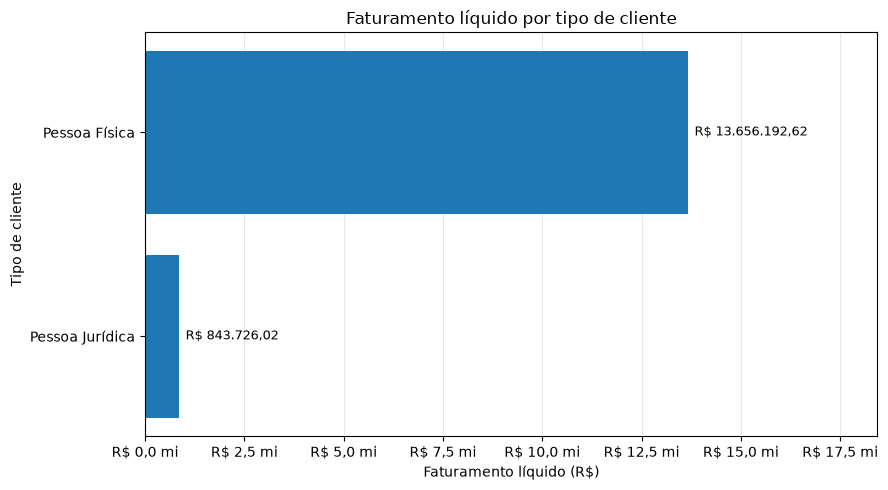

In [36]:
# Comparação do faturamento líquido por tipo de cliente

fig, ax = plt.subplots(figsize=(9, 5))

barras = ax.barh(
    desempenho_tipos_clientes["tipo_cliente"],
    desempenho_tipos_clientes["faturamento_liquido"]
)

# Colocando o maior faturamento no topo
ax.invert_yaxis()

# Adicionando os valores sobre as barras
rotulos = [
    formatar_moeda(valor)
    for valor in desempenho_tipos_clientes["faturamento_liquido"]
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=9
)

# Formatando o eixo horizontal em milhões de reais
from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, pos: (
            f"R$ {valor / 1_000_000:.1f}".replace(".", ",") + " mi"
        )
    )
)

ax.set_title("Faturamento líquido por tipo de cliente")
ax.set_xlabel("Faturamento líquido (R$)")
ax.set_ylabel("Tipo de cliente")

ax.set_xlim(
    0,
    desempenho_tipos_clientes["faturamento_liquido"].max() * 1.35
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Síntese da análise do perfil e comportamento dos clientes

A análise demonstrou que as pessoas físicas representam a maior parte da base de clientes que realizaram compras, sendo responsáveis por 94,18% do faturamento líquido da loja.

As pessoas físicas também apresentaram maior número de transações, ticket médio e receita média por cliente quando comparadas às pessoas jurídicas.

Apesar dessas diferenças, os dois grupos apresentaram margens brutas praticamente iguais, próximas de 25,23%.

Os resultados indicam que o desempenho comercial da loja está fortemente concentrado nas pessoas físicas, enquanto as pessoas jurídicas representam uma parcela menor do faturamento.

Essas informações podem auxiliar na definição de estratégias comerciais e na identificação de oportunidades para ampliar o relacionamento com clientes de ambos os grupos.

## 5.6 Análise geográfica dos clientes e das vendas

Nesta etapa, vamos investigar a distribuição geográfica dos clientes e o desempenho comercial das diferentes cidades e estados registrados na base de dados.

Serão analisados o faturamento líquido, a quantidade vendida, o número de transações, a quantidade de clientes e a participação de cada cidade no faturamento total.

O objetivo é identificar as regiões com maior contribuição comercial e compreender a distribuição geográfica das vendas da loja.

In [37]:
# Agrupando os resultados por cidade e estado

desempenho_geografico = (
    vendas_clientes
    .groupby(["estado", "cidade"])
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),
        quantidade_vendida=(
            "quantidade", "sum"
        ),
        numero_vendas=(
            "venda_id", "nunique"
        ),
        clientes_unicos=(
            "cliente_id", "nunique"
        ),
        custo_total=(
            "custo_total_item", "sum"
        ),
        lucro_bruto=(
            "lucro_bruto_item", "sum"
        )
    )
    .reset_index()
)

# Calculando o ticket médio por cidade

desempenho_geografico["ticket_medio"] = (
    desempenho_geografico["faturamento_liquido"] /
    desempenho_geografico["numero_vendas"]
)

# Calculando a receita média por cliente

desempenho_geografico["receita_media_cliente"] = (
    desempenho_geografico["faturamento_liquido"] /
    desempenho_geografico["clientes_unicos"]
)

# Calculando a margem bruta

desempenho_geografico["margem_bruta"] = (
    desempenho_geografico["lucro_bruto"] /
    desempenho_geografico["faturamento_liquido"]
) * 100

# Calculando a participação de cada cidade no faturamento

desempenho_geografico["participacao_faturamento"] = (
    desempenho_geografico["faturamento_liquido"] /
    desempenho_geografico["faturamento_liquido"].sum()
) * 100

# Ordenando as cidades pelo maior faturamento

desempenho_geografico = desempenho_geografico.sort_values(
    by="faturamento_liquido",
    ascending=False
)

# Selecionando as dez cidades de maior faturamento

dez_melhores_cidades = desempenho_geografico.head(10).copy()

display(dez_melhores_cidades)

,estado,cidade,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,custo_total,lucro_bruto,ticket_medio,receita_media_cliente,margem_bruta,participacao_faturamento
2,SP,Guaratinguetá,1865599.62,1400,614,74,1395899.0,469700.62,3038.435863,25210.805676,25.176925,12.866276
4,SP,Pindamonhangaba,1794641.10,1351,609,67,1343547.0,451094.10,2946.865517,26785.688060,25.135616,12.376905
9,SP,Taubaté,1717163.81,1325,594,64,1281962.0,435201.81,2890.848165,26830.684531,25.344222,11.842575
1,SP,Caçapava,1474091.46,1068,486,60,1102788.0,371303.46,3033.110000,24568.191000,25.188631,10.166205
5,SP,Santos,1446349.54,1059,495,62,1083276.0,363073.54,2921.918263,23328.218387,25.102752,9.974880
0,SP,Campinas,1403731.51,1091,519,57,1050994.0,352737.51,2704.684990,24626.868596,25.128560,9.680961
7,SP,São José dos Campos,1322812.09,1066,469,65,987988.0,334824.09,2820.494861,20350.955231,25.311538,9.122893
3,SP,Jacareí,1316673.05,960,444,56,982110.0,334563.05,2965.479842,23512.018750,25.409729,9.080555
6,SP,Sorocaba,1188411.97,906,417,51,887323.0,301088.97,2849.908801,23302.195490,25.335404,8.195991
8,SP,São Paulo,970444.49,775,353,46,724622.0,245822.49,2749.134533,21096.619348,25.330917,6.692758


In [38]:
# Criando uma cópia formatada para apresentação

dez_melhores_cidades_formatado = dez_melhores_cidades.copy()

# Formatação dos valores monetários

colunas_monetarias = [
    "faturamento_liquido",
    "custo_total",
    "lucro_bruto",
    "ticket_medio",
    "receita_media_cliente"
]

for coluna in colunas_monetarias:
    dez_melhores_cidades_formatado[coluna] = (
        dez_melhores_cidades_formatado[coluna]
        .apply(formatar_moeda)
    )

# Formatação das quantidades

colunas_inteiras = [
    "quantidade_vendida",
    "numero_vendas",
    "clientes_unicos"
]

for coluna in colunas_inteiras:
    dez_melhores_cidades_formatado[coluna] = (
        dez_melhores_cidades_formatado[coluna]
        .apply(formatar_inteiro)
    )

# Formatação dos percentuais

colunas_percentuais = [
    "margem_bruta",
    "participacao_faturamento"
]

for coluna in colunas_percentuais:
    dez_melhores_cidades_formatado[coluna] = (
        dez_melhores_cidades_formatado[coluna]
        .apply(formatar_percentual)
    )

display(dez_melhores_cidades_formatado)

,estado,cidade,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,custo_total,lucro_bruto,ticket_medio,receita_media_cliente,margem_bruta,participacao_faturamento
2,SP,Guaratinguetá,"R$ 1.865.599,62",1.400,614,74,"R$ 1.395.899,00","R$ 469.700,62","R$ 3.038,44","R$ 25.210,81","25,18%","12,87%"
4,SP,Pindamonhangaba,"R$ 1.794.641,10",1.351,609,67,"R$ 1.343.547,00","R$ 451.094,10","R$ 2.946,87","R$ 26.785,69","25,14%","12,38%"
9,SP,Taubaté,"R$ 1.717.163,81",1.325,594,64,"R$ 1.281.962,00","R$ 435.201,81","R$ 2.890,85","R$ 26.830,68","25,34%","11,84%"
1,SP,Caçapava,"R$ 1.474.091,46",1.068,486,60,"R$ 1.102.788,00","R$ 371.303,46","R$ 3.033,11","R$ 24.568,19","25,19%","10,17%"
5,SP,Santos,"R$ 1.446.349,54",1.059,495,62,"R$ 1.083.276,00","R$ 363.073,54","R$ 2.921,92","R$ 23.328,22","25,10%","9,97%"
0,SP,Campinas,"R$ 1.403.731,51",1.091,519,57,"R$ 1.050.994,00","R$ 352.737,51","R$ 2.704,68","R$ 24.626,87","25,13%","9,68%"
7,SP,São José dos Campos,"R$ 1.322.812,09",1.066,469,65,"R$ 987.988,00","R$ 334.824,09","R$ 2.820,49","R$ 20.350,96","25,31%","9,12%"
3,SP,Jacareí,"R$ 1.316.673,05",960,444,56,"R$ 982.110,00","R$ 334.563,05","R$ 2.965,48","R$ 23.512,02","25,41%","9,08%"
6,SP,Sorocaba,"R$ 1.188.411,97",906,417,51,"R$ 887.323,00","R$ 301.088,97","R$ 2.849,91","R$ 23.302,20","25,34%","8,20%"
8,SP,São Paulo,"R$ 970.444,49",775,353,46,"R$ 724.622,00","R$ 245.822,49","R$ 2.749,13","R$ 21.096,62","25,33%","6,69%"


In [39]:
print(
    "Estados presentes na base:",
    clientes["estado"].nunique()
)

print(
    "Cidades presentes na base:",
    clientes["cidade"].nunique()
)

print(
    "Clientes cadastrados:",
    len(clientes)
)

print(
    "Clientes que realizaram compras:",
    vendas_clientes["cliente_id"].nunique()
)

Estados presentes na base: 1
Cidades presentes na base: 10
Clientes cadastrados: 650
Clientes que realizaram compras: 602


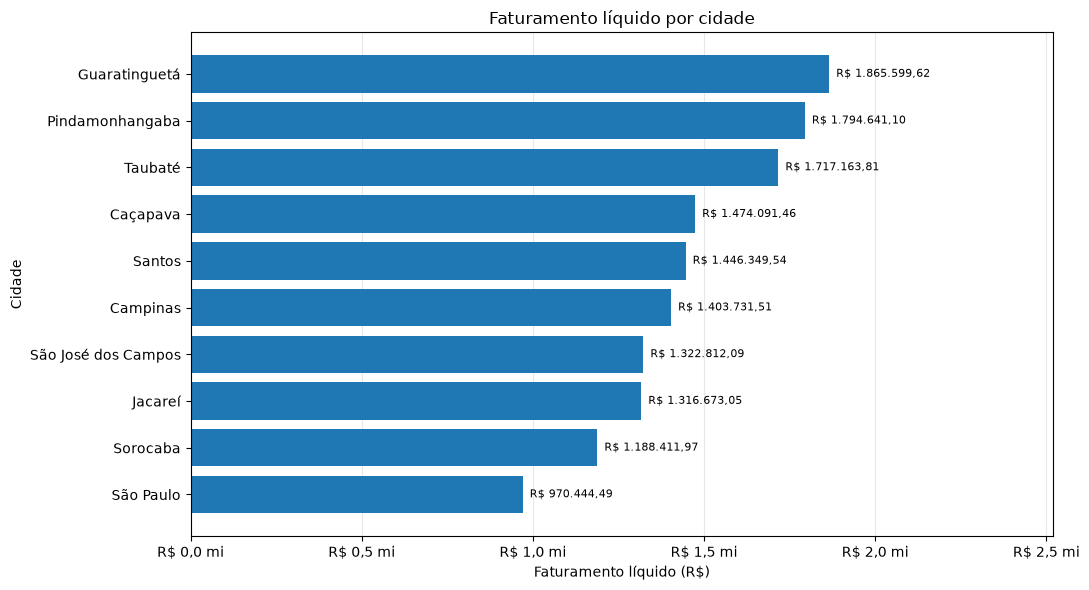

In [40]:
# Comparação do faturamento líquido por cidade

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    dez_melhores_cidades["cidade"],
    dez_melhores_cidades["faturamento_liquido"]
)

# Colocando a cidade de maior faturamento no topo
ax.invert_yaxis()

# Adicionando os valores monetários nas barras
rotulos = [
    formatar_moeda(valor)
    for valor in dez_melhores_cidades["faturamento_liquido"]
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=8
)

# Formatando o eixo em milhões de reais
from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, pos: (
            f"R$ {valor / 1_000_000:.1f}".replace(".", ",") + " mi"
        )
    )
)

ax.set_title("Faturamento líquido por cidade")
ax.set_xlabel("Faturamento líquido (R$)")
ax.set_ylabel("Cidade")

ax.set_xlim(
    0,
    dez_melhores_cidades["faturamento_liquido"].max() * 1.35
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Síntese da análise geográfica

A análise geográfica identificou dez cidades no estado de São Paulo, responsáveis pelo faturamento registrado na base simulada.

Guaratinguetá apresentou o maior faturamento, com R$ 1.865.599,62, seguida por Pindamonhangaba e Taubaté.

Taubaté destacou-se pela maior receita média por cliente, enquanto Guaratinguetá apresentou o maior ticket médio entre as cidades analisadas.

Também foi identificado que 602 dos 650 clientes cadastrados realizaram compras, correspondendo a aproximadamente 92,62% da base.

As margens brutas das cidades apresentaram pouca variação, indicando resultados de rentabilidade semelhantes entre as localidades.

Essas informações permitem compreender a distribuição geográfica do desempenho comercial e identificar cidades com maior participação no faturamento.

Como a base simulada contempla apenas cidades do estado de São Paulo, os resultados não devem ser interpretados como uma representação da distribuição geográfica nacional.

## 5.7 Análise das formas de pagamento

Nesta etapa, vamos investigar as formas de pagamento utilizadas nas compras realizadas na loja.

Serão analisados o faturamento líquido, o número de transações, a quantidade de clientes, o ticket médio e a participação de cada forma de pagamento no faturamento total.

O objetivo é compreender os hábitos de pagamento dos clientes e identificar quais modalidades possuem maior relevância para os resultados comerciais.

In [41]:
# Agrupando os resultados por forma de pagamento

desempenho_pagamentos = (
    vendas_detalhadas
    .groupby("forma_pagamento")
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),
        quantidade_vendida=(
            "quantidade", "sum"
        ),
        numero_vendas=(
            "venda_id", "nunique"
        ),
        clientes_unicos=(
            "cliente_id", "nunique"
        ),
        custo_total=(
            "custo_total_item", "sum"
        ),
        lucro_bruto=(
            "lucro_bruto_item", "sum"
        )
    )
    .reset_index()
)

# Calculando o ticket médio

desempenho_pagamentos["ticket_medio"] = (
    desempenho_pagamentos["faturamento_liquido"] /
    desempenho_pagamentos["numero_vendas"]
)

# Calculando a margem bruta

desempenho_pagamentos["margem_bruta"] = (
    desempenho_pagamentos["lucro_bruto"] /
    desempenho_pagamentos["faturamento_liquido"]
) * 100

# Calculando a participação no faturamento total

desempenho_pagamentos["participacao_faturamento"] = (
    desempenho_pagamentos["faturamento_liquido"] /
    desempenho_pagamentos["faturamento_liquido"].sum()
) * 100

# Ordenando pelo maior faturamento

desempenho_pagamentos = desempenho_pagamentos.sort_values(
    by="faturamento_liquido",
    ascending=False
)

display(desempenho_pagamentos)

,forma_pagamento,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,custo_total,lucro_bruto,ticket_medio,margem_bruta,participacao_faturamento
1,Cartão de crédito,6162273.52,4663,2124,522,4608040.0,1554233.52,2901.258719,25.221755,42.498677
3,Pix,4956280.96,3791,1711,507,3705435.0,1250845.96,2896.715932,25.237592,34.181440
2,Cartão de débito,2754853.79,2035,915,411,2060360.0,694493.79,3010.769169,25.209824,18.999098
0,Boleto,626510.37,512,250,198,466674.0,159836.37,2506.041480,25.512167,4.320785


In [42]:
# Criando uma cópia formatada para apresentação

desempenho_pagamentos_formatado = desempenho_pagamentos.copy()

# Formatação dos valores monetários

colunas_monetarias = [
    "faturamento_liquido",
    "custo_total",
    "lucro_bruto",
    "ticket_medio"
]

for coluna in colunas_monetarias:
    desempenho_pagamentos_formatado[coluna] = (
        desempenho_pagamentos_formatado[coluna]
        .apply(formatar_moeda)
    )

# Formatação das quantidades

colunas_inteiras = [
    "quantidade_vendida",
    "numero_vendas",
    "clientes_unicos"
]

for coluna in colunas_inteiras:
    desempenho_pagamentos_formatado[coluna] = (
        desempenho_pagamentos_formatado[coluna]
        .apply(formatar_inteiro)
    )

# Formatação dos percentuais

colunas_percentuais = [
    "margem_bruta",
    "participacao_faturamento"
]

for coluna in colunas_percentuais:
    desempenho_pagamentos_formatado[coluna] = (
        desempenho_pagamentos_formatado[coluna]
        .apply(formatar_percentual)
    )

display(desempenho_pagamentos_formatado)

,forma_pagamento,faturamento_liquido,quantidade_vendida,numero_vendas,clientes_unicos,custo_total,lucro_bruto,ticket_medio,margem_bruta,participacao_faturamento
1,Cartão de crédito,"R$ 6.162.273,52",4.663,2.124,522,"R$ 4.608.040,00","R$ 1.554.233,52","R$ 2.901,26","25,22%","42,50%"
3,Pix,"R$ 4.956.280,96",3.791,1.711,507,"R$ 3.705.435,00","R$ 1.250.845,96","R$ 2.896,72","25,24%","34,18%"
2,Cartão de débito,"R$ 2.754.853,79",2.035,915,411,"R$ 2.060.360,00","R$ 694.493,79","R$ 3.010,77","25,21%","19,00%"
0,Boleto,"R$ 626.510,37",512,250,198,"R$ 466.674,00","R$ 159.836,37","R$ 2.506,04","25,51%","4,32%"


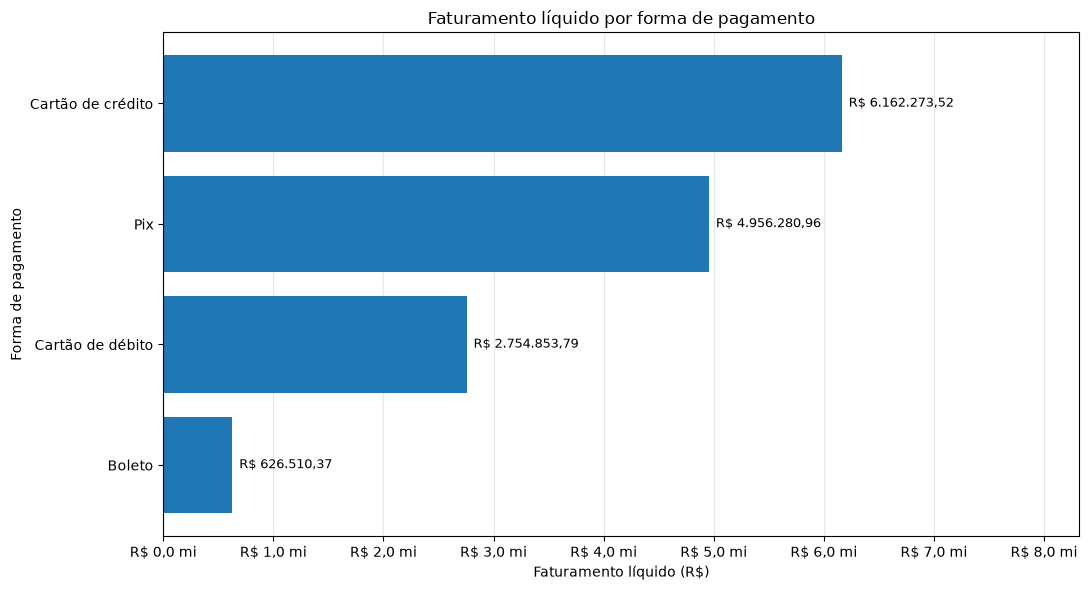

In [43]:
# Comparação do faturamento líquido por forma de pagamento

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    desempenho_pagamentos["forma_pagamento"],
    desempenho_pagamentos["faturamento_liquido"]
)

# Colocando a maior modalidade no topo
ax.invert_yaxis()

# Adicionando os valores monetários nas barras

rotulos = [
    formatar_moeda(valor)
    for valor in desempenho_pagamentos["faturamento_liquido"]
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=9
)

# Formatando o eixo em milhões de reais

from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, pos: (
            f"R$ {valor / 1_000_000:.1f}".replace(".", ",") + " mi"
        )
    )
)

ax.set_title("Faturamento líquido por forma de pagamento")
ax.set_xlabel("Faturamento líquido (R$)")
ax.set_ylabel("Forma de pagamento")

ax.set_xlim(
    0,
    desempenho_pagamentos["faturamento_liquido"].max() * 1.35
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [44]:
# Criando uma tabela específica para analisar as formas de pagamento

desempenho_pagamentos_resumido = desempenho_pagamentos[
    [
        "forma_pagamento",
        "numero_vendas",
        "faturamento_liquido",
        "ticket_medio",
        "participacao_faturamento"
    ]
].copy()

# Calculando a participação de cada modalidade no número de vendas

desempenho_pagamentos_resumido["participacao_vendas"] = (
    desempenho_pagamentos_resumido["numero_vendas"] /
    desempenho_pagamentos_resumido["numero_vendas"].sum()
) * 100

# Organizando as colunas

desempenho_pagamentos_resumido = (
    desempenho_pagamentos_resumido[
        [
            "forma_pagamento",
            "numero_vendas",
            "participacao_vendas",
            "faturamento_liquido",
            "participacao_faturamento",
            "ticket_medio"
        ]
    ]
)

# Criando cópia formatada

pagamentos_formatados = desempenho_pagamentos_resumido.copy()

pagamentos_formatados["numero_vendas"] = (
    pagamentos_formatados["numero_vendas"]
    .apply(formatar_inteiro)
)

pagamentos_formatados["faturamento_liquido"] = (
    pagamentos_formatados["faturamento_liquido"]
    .apply(formatar_moeda)
)

pagamentos_formatados["ticket_medio"] = (
    pagamentos_formatados["ticket_medio"]
    .apply(formatar_moeda)
)

for coluna in ["participacao_vendas", "participacao_faturamento"]:
    pagamentos_formatados[coluna] = (
        pagamentos_formatados[coluna]
        .apply(formatar_percentual)
    )

display(pagamentos_formatados)

,forma_pagamento,numero_vendas,participacao_vendas,faturamento_liquido,participacao_faturamento,ticket_medio
1,Cartão de crédito,2.124,"42,48%","R$ 6.162.273,52","42,50%","R$ 2.901,26"
3,Pix,1.711,"34,22%","R$ 4.956.280,96","34,18%","R$ 2.896,72"
2,Cartão de débito,915,"18,30%","R$ 2.754.853,79","19,00%","R$ 3.010,77"
0,Boleto,250,"5,00%","R$ 626.510,37","4,32%","R$ 2.506,04"


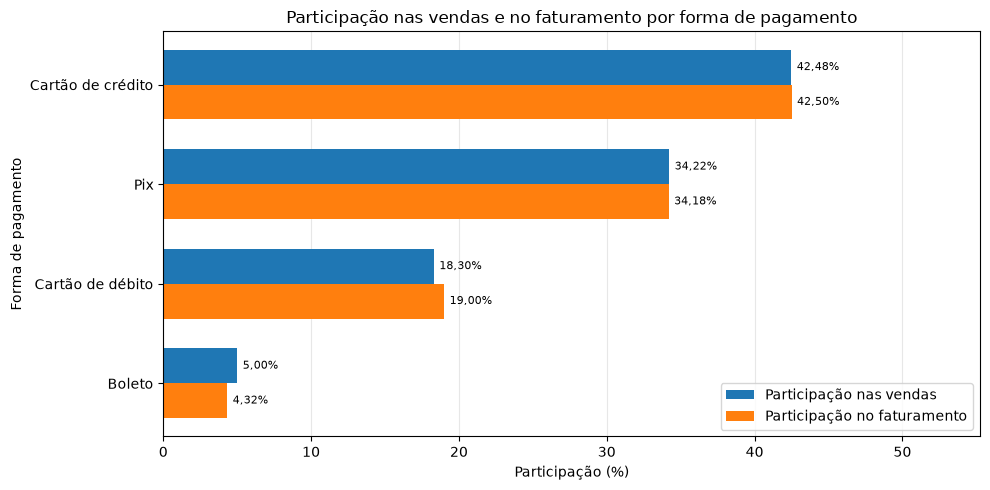

In [45]:
# Comparação da participação nas vendas e no faturamento

fig, ax = plt.subplots(figsize=(10, 5))

posicoes = range(len(desempenho_pagamentos_resumido))
altura = 0.35

barras_vendas = ax.barh(
    [p - altura / 2 for p in posicoes],
    desempenho_pagamentos_resumido["participacao_vendas"],
    height=altura,
    label="Participação nas vendas"
)

barras_faturamento = ax.barh(
    [p + altura / 2 for p in posicoes],
    desempenho_pagamentos_resumido["participacao_faturamento"],
    height=altura,
    label="Participação no faturamento"
)

ax.bar_label(
    barras_vendas,
    labels=[
        formatar_percentual(valor)
        for valor in desempenho_pagamentos_resumido["participacao_vendas"]
    ],
    padding=4,
    fontsize=8
)

ax.bar_label(
    barras_faturamento,
    labels=[
        formatar_percentual(valor)
        for valor in desempenho_pagamentos_resumido["participacao_faturamento"]
    ],
    padding=4,
    fontsize=8
)

ax.set_yticks(list(posicoes))
ax.set_yticklabels(
    desempenho_pagamentos_resumido["forma_pagamento"]
)

ax.invert_yaxis()

ax.set_title("Participação nas vendas e no faturamento por forma de pagamento")
ax.set_xlabel("Participação (%)")
ax.set_ylabel("Forma de pagamento")

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

ax.set_xlim(
    0,
    desempenho_pagamentos_resumido[
        ["participacao_vendas", "participacao_faturamento"]
    ].to_numpy().max() * 1.30
)

plt.tight_layout()
plt.show()

### Síntese da análise das formas de pagamento

A análise identificou o cartão de crédito como a modalidade com maior utilização e participação no faturamento, seguido pelo Pix.

O cartão de débito apresentou o maior ticket médio, indicando um valor médio por transação superior ao das demais modalidades.

O boleto apresentou a menor participação no faturamento e o menor ticket médio.

As diferenças entre a participação nas transações e no faturamento permitem observar como cada modalidade contribui para os resultados comerciais da loja.

## 5.8 Análise e diagnóstico de estoque

Nesta etapa, vamos investigar a situação atual do estoque da loja, comparando a quantidade disponível de cada produto com seu respectivo estoque mínimo.

Também relacionaremos as informações de estoque com o histórico de vendas, permitindo identificar produtos com maior movimentação comercial e possíveis necessidades de atenção.

O objetivo é identificar produtos abaixo ou próximos do estoque mínimo e fornecer informações que possam auxiliar nas decisões de reposição.

A base de estoque representa uma fotografia em uma única data de referência, não sendo possível analisar o histórico de movimentação ou reposição dos produtos.

In [46]:
# Resumindo o histórico de vendas por produto

vendas_por_produto_estoque = (
    itens_produtos
    .groupby("produto_id")
    .agg(
        quantidade_vendida=("quantidade", "sum"),
        faturamento_liquido=("faturamento_liquido_item", "sum")
    )
    .reset_index()
)

# Relacionando produtos com seus respectivos registros de estoque

analise_estoque = produtos[
    [
        "produto_id",
        "nome_produto",
        "categoria",
        "marca"
    ]
].merge(
    estoque[
        [
            "produto_id",
            "quantidade_disponivel",
            "estoque_minimo",
            "data_referencia"
        ]
    ],
    on="produto_id",
    how="left",
    validate="one_to_one"
).merge(
    vendas_por_produto_estoque,
    on="produto_id",
    how="left",
    validate="one_to_one"
)

# Produtos sem vendas registradas recebem quantidade e faturamento zero
analise_estoque[
    ["quantidade_vendida", "faturamento_liquido"]
] = analise_estoque[
    ["quantidade_vendida", "faturamento_liquido"]
].fillna(0)

analise_estoque["quantidade_vendida"] = (
    analise_estoque["quantidade_vendida"].astype(int)
)

# Calculando a diferença entre estoque disponível e estoque mínimo

analise_estoque["diferenca_para_minimo"] = (
    analise_estoque["quantidade_disponivel"] -
    analise_estoque["estoque_minimo"]
)

# Classificando a situação de cada produto

analise_estoque["situacao_estoque"] = analise_estoque.apply(
    lambda linha:
        "Abaixo do mínimo"
        if linha["quantidade_disponivel"] < linha["estoque_minimo"]
        else "No mínimo"
        if linha["quantidade_disponivel"] == linha["estoque_minimo"]
        else "Acima do mínimo",
    axis=1
)

# Ordenando os produtos que exigem maior atenção

analise_estoque = analise_estoque.sort_values(
    by=["diferenca_para_minimo", "quantidade_vendida"],
    ascending=[True, False]
).reset_index(drop=True)

display(analise_estoque)

,produto_id,nome_produto,categoria,marca,quantidade_disponivel,estoque_minimo,data_referencia,quantidade_vendida,faturamento_liquido,diferenca_para_minimo,situacao_estoque
0,P019,Tablet Kids 8,Tablets,Multilaser,5,10,2026-10-31,176,102133.34,-5,Abaixo do mínimo
1,P016,Computador Gamer G1,Computadores,Acer,0,5,2026-10-31,107,588030.24,-5,Abaixo do mínimo
2,P023,Teclado Mecânico,Periféricos,Redragon,11,15,2026-10-31,379,109758.87,-4,Abaixo do mínimo
3,P026,Webcam Full HD,Periféricos,Logitech,11,15,2026-10-31,349,84188.62,-4,Abaixo do mínimo
4,P008,Smartphone Plus B,Smartphones,Motorola,2,5,2026-10-31,384,519345.08,-3,Abaixo do mínimo
5,P029,Capa para Smartphone,Acessórios,Genérica,3,5,2026-10-31,513,17407.34,-2,Abaixo do mínimo
6,P011,Smartphone Max E,Smartphones,Xiaomi,10,12,2026-10-31,334,939218.34,-2,Abaixo do mínimo
7,P009,Smartphone Pro C,Smartphones,Samsung,10,12,2026-10-31,235,569842.87,-2,Abaixo do mínimo
8,P006,Notebook Work 16,Notebooks,Lenovo,14,15,2026-10-31,238,1102431.68,-1,Abaixo do mínimo
9,P017,Tablet Study 10,Tablets,Samsung,14,15,2026-10-31,187,181136.61,-1,Abaixo do mínimo


In [47]:
# Criando uma cópia formatada para apresentação

analise_estoque_formatada = analise_estoque.copy()

# Formatação dos valores monetários

analise_estoque_formatada["faturamento_liquido"] = (
    analise_estoque_formatada["faturamento_liquido"]
    .apply(formatar_moeda)
)

# Formatação das quantidades

colunas_inteiras = [
    "quantidade_disponivel",
    "estoque_minimo",
    "quantidade_vendida",
    "diferenca_para_minimo"
]

for coluna in colunas_inteiras:
    analise_estoque_formatada[coluna] = (
        analise_estoque_formatada[coluna]
        .apply(formatar_inteiro)
    )

display(analise_estoque_formatada)

,produto_id,nome_produto,categoria,marca,quantidade_disponivel,estoque_minimo,data_referencia,quantidade_vendida,faturamento_liquido,diferenca_para_minimo,situacao_estoque
0,P019,Tablet Kids 8,Tablets,Multilaser,5,10,2026-10-31,176,"R$ 102.133,34",-5,Abaixo do mínimo
1,P016,Computador Gamer G1,Computadores,Acer,0,5,2026-10-31,107,"R$ 588.030,24",-5,Abaixo do mínimo
2,P023,Teclado Mecânico,Periféricos,Redragon,11,15,2026-10-31,379,"R$ 109.758,87",-4,Abaixo do mínimo
3,P026,Webcam Full HD,Periféricos,Logitech,11,15,2026-10-31,349,"R$ 84.188,62",-4,Abaixo do mínimo
4,P008,Smartphone Plus B,Smartphones,Motorola,2,5,2026-10-31,384,"R$ 519.345,08",-3,Abaixo do mínimo
5,P029,Capa para Smartphone,Acessórios,Genérica,3,5,2026-10-31,513,"R$ 17.407,34",-2,Abaixo do mínimo
6,P011,Smartphone Max E,Smartphones,Xiaomi,10,12,2026-10-31,334,"R$ 939.218,34",-2,Abaixo do mínimo
7,P009,Smartphone Pro C,Smartphones,Samsung,10,12,2026-10-31,235,"R$ 569.842,87",-2,Abaixo do mínimo
8,P006,Notebook Work 16,Notebooks,Lenovo,14,15,2026-10-31,238,"R$ 1.102.431,68",-1,Abaixo do mínimo
9,P017,Tablet Study 10,Tablets,Samsung,14,15,2026-10-31,187,"R$ 181.136,61",-1,Abaixo do mínimo


In [48]:
# Contabilizando produtos por situação de estoque

resumo_estoque = (
    analise_estoque
    .groupby("situacao_estoque")
    .agg(
        quantidade_produtos=("produto_id", "count")
    )
    .reset_index()
)

print(
    "Data de referência do estoque:",
    analise_estoque["data_referencia"].max().strftime("%d/%m/%Y")
)

print(
    "Total de produtos analisados:",
    len(analise_estoque)
)

display(resumo_estoque)

Data de referência do estoque: 31/10/2026
Total de produtos analisados: 36


,situacao_estoque,quantidade_produtos
0,Abaixo do mínimo,10
1,Acima do mínimo,24
2,No mínimo,2


In [49]:
# Selecionando produtos abaixo ou exatamente no estoque mínimo

produtos_atencao = analise_estoque[
    analise_estoque["situacao_estoque"].isin(
        ["Abaixo do mínimo", "No mínimo"]
    )
][
    [
        "nome_produto",
        "categoria",
        "quantidade_disponivel",
        "estoque_minimo",
        "diferenca_para_minimo",
        "quantidade_vendida",
        "faturamento_liquido",
        "situacao_estoque"
    ]
].copy()

display(produtos_atencao)

,nome_produto,categoria,quantidade_disponivel,estoque_minimo,diferenca_para_minimo,quantidade_vendida,faturamento_liquido,situacao_estoque
0,Tablet Kids 8,Tablets,5,10,-5,176,102133.34,Abaixo do mínimo
1,Computador Gamer G1,Computadores,0,5,-5,107,588030.24,Abaixo do mínimo
2,Teclado Mecânico,Periféricos,11,15,-4,379,109758.87,Abaixo do mínimo
3,Webcam Full HD,Periféricos,11,15,-4,349,84188.62,Abaixo do mínimo
4,Smartphone Plus B,Smartphones,2,5,-3,384,519345.08,Abaixo do mínimo
5,Capa para Smartphone,Acessórios,3,5,-2,513,17407.34,Abaixo do mínimo
6,Smartphone Max E,Smartphones,10,12,-2,334,939218.34,Abaixo do mínimo
7,Smartphone Pro C,Smartphones,10,12,-2,235,569842.87,Abaixo do mínimo
8,Notebook Work 16,Notebooks,14,15,-1,238,1102431.68,Abaixo do mínimo
9,Tablet Study 10,Tablets,14,15,-1,187,181136.61,Abaixo do mínimo


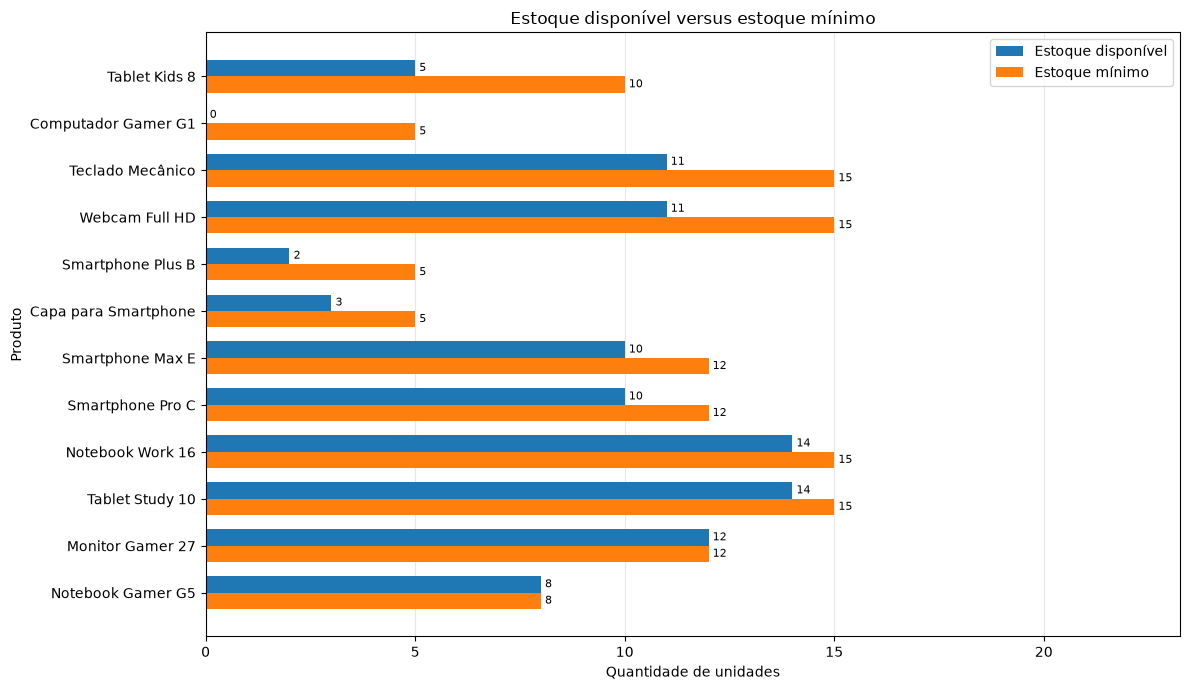

In [50]:
# Comparando estoque disponível e estoque mínimo

fig, ax = plt.subplots(figsize=(12, 7))

posicoes = range(len(produtos_atencao))
altura = 0.35

barras_disponivel = ax.barh(
    [p - altura / 2 for p in posicoes],
    produtos_atencao["quantidade_disponivel"],
    height=altura,
    label="Estoque disponível"
)

barras_minimo = ax.barh(
    [p + altura / 2 for p in posicoes],
    produtos_atencao["estoque_minimo"],
    height=altura,
    label="Estoque mínimo"
)

# Adicionando os valores nas barras

ax.bar_label(
    barras_disponivel,
    labels=[
        formatar_inteiro(v)
        for v in produtos_atencao["quantidade_disponivel"]
    ],
    padding=3,
    fontsize=8
)

ax.bar_label(
    barras_minimo,
    labels=[
        formatar_inteiro(v)
        for v in produtos_atencao["estoque_minimo"]
    ],
    padding=3,
    fontsize=8
)

ax.set_yticks(list(posicoes))
ax.set_yticklabels(produtos_atencao["nome_produto"])

ax.invert_yaxis()

ax.set_title("Estoque disponível versus estoque mínimo")
ax.set_xlabel("Quantidade de unidades")
ax.set_ylabel("Produto")

ax.legend()
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

ax.set_xlim(
    0,
    produtos_atencao["estoque_minimo"].max() * 1.55
)

plt.tight_layout()
plt.show()

### Síntese da análise e diagnóstico de estoque

A análise identificou que 10 dos 36 produtos estão abaixo do estoque mínimo estabelecido, enquanto outros dois estão exatamente nesse limite.

Entre os casos de maior atenção, destaca-se o Computador Gamer G1, que apresenta estoque disponível igual a zero, apesar de possuir histórico de vendas.

Também foram identificados produtos com estoque inferior ao mínimo e movimentação comercial relevante, como Notebook Work 16, Smartphone Max E e Teclado Mecânico.

Considerando os dez produtos abaixo do mínimo, existe uma diferença acumulada de 29 unidades em relação aos respectivos níveis mínimos.

Os resultados demonstram a importância de acompanhar conjuntamente a disponibilidade de estoque, os limites mínimos definidos e o histórico de vendas.

Como a base de estoque representa uma fotografia de 31/10/2026, não é possível determinar o comportamento histórico do estoque ou calcular com precisão o momento de uma futura ruptura. Para recomendações mais completas, serão necessários dados adicionais sobre reposição, fornecedores e demanda recente.

## 5.9 Análise de desempenho por marca

Nesta etapa, vamos comparar o desempenho comercial das marcas presentes no catálogo da loja.

Serão analisados o faturamento líquido, a quantidade vendida, o número de transações, a quantidade de produtos distintos e o lucro bruto de cada marca.

O objetivo é identificar quais marcas possuem maior contribuição para os resultados comerciais e financeiros da loja.

In [51]:
# Agrupando os resultados por marca

desempenho_marcas = (
    itens_produtos
    .groupby("marca")
    .agg(
        faturamento_liquido=(
            "faturamento_liquido_item", "sum"
        ),
        quantidade_vendida=(
            "quantidade", "sum"
        ),
        numero_vendas=(
            "venda_id", "nunique"
        ),
        produtos_distintos=(
            "produto_id", "nunique"
        ),
        custo_total=(
            "custo_total_item", "sum"
        ),
        lucro_bruto=(
            "lucro_bruto_item", "sum"
        )
    )
    .reset_index()
)

# Calculando a margem bruta

desempenho_marcas["margem_bruta"] = (
    desempenho_marcas["lucro_bruto"] /
    desempenho_marcas["faturamento_liquido"]
) * 100

# Calculando a participação no faturamento

desempenho_marcas["participacao_faturamento"] = (
    desempenho_marcas["faturamento_liquido"] /
    desempenho_marcas["faturamento_liquido"].sum()
) * 100

# Ordenando pelo maior faturamento

desempenho_marcas = desempenho_marcas.sort_values(
    by="faturamento_liquido",
    ascending=False
).reset_index(drop=True)

display(desempenho_marcas)

,marca,faturamento_liquido,quantidade_vendida,numero_vendas,produtos_distintos,custo_total,lucro_bruto,margem_bruta,participacao_faturamento
0,Lenovo,3092576.27,927,893,4,2353150.0,739426.27,23.909718,21.328232
1,Acer,2474567.98,518,506,3,1913620.0,560947.98,22.668522,17.066082
2,Dell,1823406.59,434,426,2,1401010.0,422396.59,23.165244,12.575288
3,Xiaomi,1254949.72,606,589,2,924440.0,330509.72,26.336491,8.654874
4,Motorola,1112576.55,691,660,2,798430.0,314146.55,28.235949,7.672985
5,Samsung,1007810.14,1055,871,4,745268.0,262542.14,26.050754,6.950454
6,AOC,824033.29,531,446,1,594720.0,229313.29,27.828158,5.683020
7,ASUS,749591.46,180,180,1,576000.0,173591.46,23.158143,5.169625
8,Apple,657582.44,219,219,1,514650.0,142932.44,21.736049,4.535077
9,Positivo,422838.20,182,182,1,318500.0,104338.20,24.675680,2.916142


In [52]:
# Criando uma cópia formatada para apresentação

desempenho_marcas_formatado = desempenho_marcas.copy()

# Formatação dos valores monetários

colunas_monetarias = [
    "faturamento_liquido",
    "custo_total",
    "lucro_bruto"
]

for coluna in colunas_monetarias:
    desempenho_marcas_formatado[coluna] = (
        desempenho_marcas_formatado[coluna]
        .apply(formatar_moeda)
    )

# Formatação das quantidades

colunas_inteiras = [
    "quantidade_vendida",
    "numero_vendas",
    "produtos_distintos"
]

for coluna in colunas_inteiras:
    desempenho_marcas_formatado[coluna] = (
        desempenho_marcas_formatado[coluna]
        .apply(formatar_inteiro)
    )

# Formatação dos percentuais

colunas_percentuais = [
    "margem_bruta",
    "participacao_faturamento"
]

for coluna in colunas_percentuais:
    desempenho_marcas_formatado[coluna] = (
        desempenho_marcas_formatado[coluna]
        .apply(formatar_percentual)
    )

display(desempenho_marcas_formatado)

,marca,faturamento_liquido,quantidade_vendida,numero_vendas,produtos_distintos,custo_total,lucro_bruto,margem_bruta,participacao_faturamento
0,Lenovo,"R$ 3.092.576,27",927,893,4,"R$ 2.353.150,00","R$ 739.426,27","23,91%","21,33%"
1,Acer,"R$ 2.474.567,98",518,506,3,"R$ 1.913.620,00","R$ 560.947,98","22,67%","17,07%"
2,Dell,"R$ 1.823.406,59",434,426,2,"R$ 1.401.010,00","R$ 422.396,59","23,17%","12,58%"
3,Xiaomi,"R$ 1.254.949,72",606,589,2,"R$ 924.440,00","R$ 330.509,72","26,34%","8,65%"
4,Motorola,"R$ 1.112.576,55",691,660,2,"R$ 798.430,00","R$ 314.146,55","28,24%","7,67%"
5,Samsung,"R$ 1.007.810,14",1.055,871,4,"R$ 745.268,00","R$ 262.542,14","26,05%","6,95%"
6,AOC,"R$ 824.033,29",531,446,1,"R$ 594.720,00","R$ 229.313,29","27,83%","5,68%"
7,ASUS,"R$ 749.591,46",180,180,1,"R$ 576.000,00","R$ 173.591,46","23,16%","5,17%"
8,Apple,"R$ 657.582,44",219,219,1,"R$ 514.650,00","R$ 142.932,44","21,74%","4,54%"
9,Positivo,"R$ 422.838,20",182,182,1,"R$ 318.500,00","R$ 104.338,20","24,68%","2,92%"


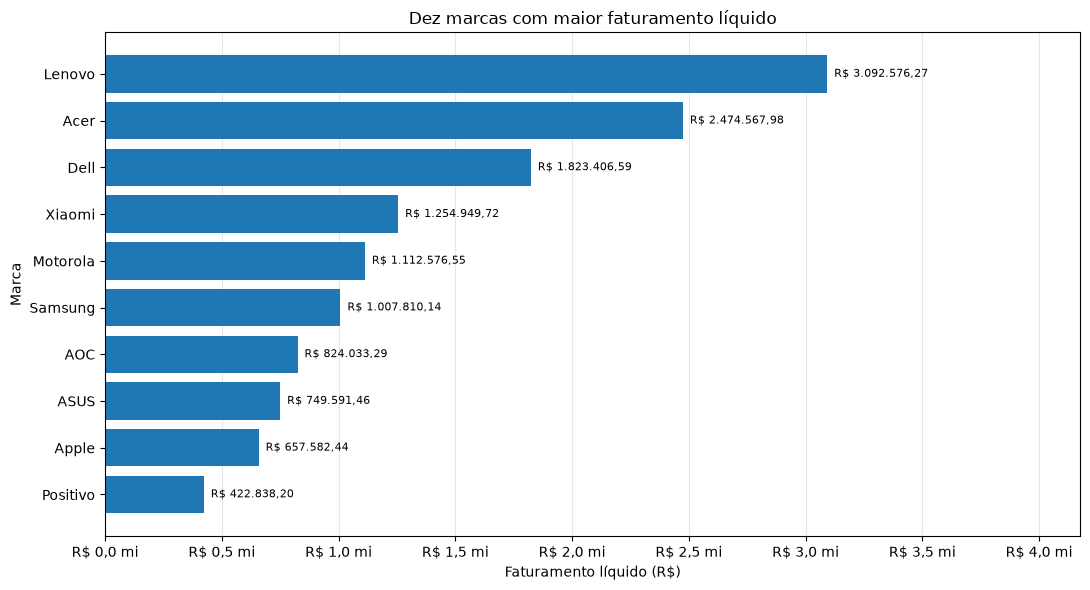

In [53]:
# Selecionando as dez marcas de maior faturamento

dez_melhores_marcas = (
    desempenho_marcas
    .head(10)
    .copy()
)

# Criando o gráfico

fig, ax = plt.subplots(figsize=(11, 6))

barras = ax.barh(
    dez_melhores_marcas["marca"],
    dez_melhores_marcas["faturamento_liquido"]
)

# Colocando a maior marca no topo

ax.invert_yaxis()

# Adicionando os valores nas barras

rotulos = [
    formatar_moeda(valor)
    for valor in dez_melhores_marcas["faturamento_liquido"]
]

ax.bar_label(
    barras,
    labels=rotulos,
    padding=5,
    fontsize=8
)

# Formatação do eixo em milhões de reais

from matplotlib.ticker import FuncFormatter

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda valor, pos: (
            f"R$ {valor / 1_000_000:.1f}".replace(".", ",") + " mi"
        )
    )
)

ax.set_title("Dez marcas com maior faturamento líquido")
ax.set_xlabel("Faturamento líquido (R$)")
ax.set_ylabel("Marca")

ax.set_xlim(
    0,
    dez_melhores_marcas["faturamento_liquido"].max() * 1.35
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Síntese da análise de desempenho por marca

A análise identificou 21 marcas presentes nos produtos comercializados pela loja.

A Lenovo apresentou o maior faturamento líquido, totalizando R$ 3.092.576,27, seguida pela Acer e pela Dell. Juntas, essas três marcas representam aproximadamente 50,97% do faturamento total.

A Samsung apresentou a maior quantidade de unidades vendidas, com 1.055 unidades, demonstrando que volume comercial e faturamento não representam necessariamente o mesmo desempenho.

A marca Genérica apresentou a maior margem bruta, de 61,86%, embora represente uma parcela pequena do faturamento.

Os resultados demonstram a importância de avaliar conjuntamente o faturamento, o volume de vendas e a margem bruta para compreender a contribuição de cada marca.

# 6. Conclusão da análise exploratória

A análise exploratória permitiu compreender diferentes aspectos do comportamento comercial e financeiro da loja fictícia de eletrônicos.

Foram investigados o comportamento temporal das vendas, o desempenho dos canais comerciais, das categorias, dos produtos e das marcas, além do perfil dos clientes, da distribuição geográfica, das formas de pagamento e da situação do estoque.

As análises identificaram concentração de faturamento em determinadas categorias, marcas e canais, diferenças no comportamento de compra dos clientes e produtos que apresentam níveis de estoque inferiores aos limites mínimos estabelecidos.

Os resultados demonstram como a integração de diferentes fontes de dados permite identificar padrões, oportunidades e possíveis problemas que podem auxiliar na tomada de decisão.

Entretanto, a base utilizada é simulada e possui limitações, como a ausência de dados históricos de movimentação de estoque e de informações sobre despesas operacionais e prazos de reposição.

As descobertas desta etapa servirão como fundamento para o desenvolvimento das próximas funcionalidades da ADÉLIA, incluindo o motor de indicadores, a identificação automática de problemas, a modelagem preditiva e a geração de recomendações.

Dessa forma, esta etapa estabelece a base analítica necessária para avançar da exploração dos dados para a construção de um sistema inteligente de apoio à decisão.